# 6. Búsqueda dispersa

La búsqueda dispersa (*scatter search*) trabaja con un conjunto pequeño de soluciones, el conjunto de referencia (*reference set*), que se arma para reunir soluciones buenas y soluciones distintas entre sí. En cada iteración, el método combina de manera sistemática las soluciones de ese conjunto, mejora los resultados con una búsqueda local y decide cuáles entran al conjunto. A diferencia de otros métodos poblacionales, la diversidad se controla de forma explícita al construir el conjunto de referencia, con una medida de distancia entre soluciones.

El capítulo trae dos ejemplos. El primero es el problema de la mochila, con una demostración paso a paso sobre una instancia de cinco ítems, dos comparaciones de parámetros y tres instancias más grandes. El segundo es un problema de flujo mínimo en una red con cotas inferiores en los arcos, cuya solución se compara con la de un modelo lineal resuelto con `linprog`.

## El problema de la mochila

### El problema y la representación

Hay $n$ ítems, cada uno con peso $w_j$ y valor $v_j$, y una mochila de capacidad $W$. Una solución es un vector binario $\mathbf{x} \in \{0,1\}^n$, donde $x_j = 1$ indica que el ítem $j$ va en la mochila. El método `evaluar_solucion` asigna a cada vector el valor de los ítems elegidos si cabe en la mochila y cero si no cabe,

$$f(\mathbf{x}) = \begin{cases} \sum_{j} v_j x_j & \text{si } \sum_{j} w_j x_j \le W, \\ 0 & \text{en otro caso,} \end{cases}$$

y la búsqueda maximiza $f$.

### Los cinco componentes

La clase `ScatterSearch` implementa los cinco componentes del método con los siguientes métodos.

1. Generación de diversidad (`generar_poblacion_diversa`). Crea `tam_poblacion` vectores aleatorios en los que cada bit vale 0 o 1 con probabilidad 1/2. La diversidad de esta población viene solo del azar, porque el método no controla la distancia entre las soluciones que genera.
2. Mejora (`mejorar_solucion`). Recorre los ítems en orden, invierte un bit y acepta el cambio si el valor sube estrictamente; la siguiente prueba parte de la solución aceptada. Es una sola pasada de primera mejora. Como una solución que no cabe vale cero, sacar un ítem que la vuelve factible cuenta como mejora.
3. Actualización del conjunto de referencia (`actualizar_refset`). Ordena las candidatas por valor y toma las $\lfloor b/2 \rfloor$ mejores, donde $b$ es `tam_refset`. Del resto toma otras $\lfloor b/2 \rfloor$, una a la vez, con el criterio de la máxima distancia mínima,

   $$\mathbf{x}^{*} = \arg\max_{\mathbf{x} \in C} \; \min_{\mathbf{y} \in R} d_H(\mathbf{x}, \mathbf{y}),$$

   donde $R$ es el conjunto de referencia en construcción, $C$ las candidatas que quedan y $d_H$ la distancia de Hamming, que cuenta las posiciones en que dos vectores difieren.
4. Generación de subconjuntos (`generar_combinaciones`). Forma todos los pares del conjunto de referencia, que son $b(b-1)/2$ cuando el conjunto está completo.
5. Combinación (`combinar_soluciones`). Aplica un cruce de un punto. Sortea $k$ uniforme en $\{1, \dots, n-1\}$ y forma el hijo con los primeros $k$ bits del primer padre y los demás del segundo. Cada hijo pasa por la mejora antes de competir por un lugar.

El equilibrio entre calidad y diversidad está en el tercer componente. La mitad del conjunto se llena por valor, lo que concentra la búsqueda alrededor de las mejores soluciones, y la otra mitad por distancia, lo que obliga a combinar también soluciones alejadas de ellas. El capítulo 1 trata las medidas de distancia entre soluciones.

Tres detalles de la implementación pesan en los resultados. Cuando $b$ es impar, el conjunto queda con $b-1$ soluciones. El método `actualizar_refset` construye el conjunto solo con la lista que recibe en su segundo argumento; en el ciclo principal esa lista es el conjunto actual más las soluciones nuevas, así que las soluciones del conjunto compiten con las recién creadas. Las soluciones repetidas no se filtran, de modo que una misma solución puede ocupar varios de los lugares por calidad.

El método `ejecutar` repite la combinación, la mejora y la actualización durante `max_iter` iteraciones. Además, cuando el número de la iteración (contado desde cero) es positivo y múltiplo de `diversificacion_iter`, genera una población aleatoria nueva y reconstruye el conjunto de referencia con ella. Como `actualizar_refset` usa solo la lista que recibe, en ese momento el conjunto se reemplaza por completo y la mejor solución sobrevive únicamente en el atributo `mejor_solucion`. La curva de convergencia registra el mejor valor encontrado hasta cada iteración, de modo que nunca baja.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import random
from collections import deque

In [2]:
class ScatterSearch:
    """
    Implementación del algoritmo Scatter Search para el problema de la mochila.
    
    El algoritmo Scatter Search es una metaheurística evolutiva que combina soluciones
    de un conjunto de referencia para generar nuevas soluciones, aplicando mejoras
    locales y manteniendo diversidad en la población.
    
    Atributos:
        pesos (list): Lista de pesos de cada ítem.
        valores (list): Lista de valores de cada ítem.
        capacidad_maxima (float): Capacidad máxima de la mochila.
        n_items (int): Número total de ítems disponibles.
        tam_poblacion (int): Tamaño de la población inicial.
        tam_refset (int): Tamaño del conjunto de referencia.
        max_iter (int): Número máximo de iteraciones.
        diversificacion_iter (int): Frecuencia de diversificación.
        mejor_solucion (list): Mejor solución encontrada.
        mejor_valor (float): Valor de la mejor solución encontrada.
        historial_fitness (list): Historial de los mejores valores en cada iteración.
    """
    def __init__(self, pesos, valores, capacidad_maxima, tam_poblacion=10, tam_refset=5, 
                 max_iter=100, diversificacion_iter=20):
        """
        Inicializa el algoritmo Scatter Search con los parámetros del problema.
        
        Args:
            pesos (list): Lista de pesos de cada ítem.
            valores (list): Lista de valores de cada ítem.
            capacidad_maxima (float): Capacidad máxima de la mochila.
            tam_poblacion (int, opcional): Tamaño de la población inicial. Por defecto 10.
            tam_refset (int, opcional): Tamaño del conjunto de referencia. Por defecto 5.
            max_iter (int, opcional): Número máximo de iteraciones. Por defecto 100.
            diversificacion_iter (int, opcional): Frecuencia de diversificación. Por defecto 20.
        """
        self.pesos = pesos
        self.valores = valores
        self.capacidad_maxima = capacidad_maxima
        self.n_items = len(pesos)
        self.tam_poblacion = tam_poblacion
        self.tam_refset = tam_refset
        self.max_iter = max_iter
        self.diversificacion_iter = diversificacion_iter
        self.mejor_solucion = None
        self.mejor_valor = 0
        self.historial_fitness = []
    
    def generar_solucion_aleatoria(self):
        """
        Genera una solución aleatoria para el problema de la mochila.
        
        Cada solución es un vector binario donde 1 indica que el ítem está en la mochila
        y 0 que no está incluido.
        
        Returns:
            list: Vector binario que representa una solución aleatoria.
        """
        return [random.randint(0, 1) for _ in range(self.n_items)]
    
    def evaluar_solucion(self, solucion):
        """
        Evalúa una solución para el problema de la mochila.
        
        Calcula el valor total de los ítems seleccionados. Si el peso total excede
        la capacidad máxima, la solución se considera inválida y devuelve 0.
        
        Args:
            solucion (list): Vector binario que representa una solución.
            
        Returns:
            float: Valor total de la solución, o 0 si excede la capacidad.
        """
        peso_total = sum(self.pesos[i] * solucion[i] for i in range(self.n_items))
        valor_total = sum(self.valores[i] * solucion[i] for i in range(self.n_items))
        
        # Si excede la capacidad, penalizar
        if peso_total > self.capacidad_maxima:
            return 0
        return valor_total
    
    def distancia_hamming(self, sol1, sol2):
        """
        Calcula la distancia de Hamming entre dos soluciones.
        
        La distancia de Hamming cuenta el número de posiciones en las que
        los elementos correspondientes de dos vectores son diferentes.
        
        Args:
            sol1 (list): Primera solución.
            sol2 (list): Segunda solución.
            
        Returns:
            int: Distancia de Hamming entre las dos soluciones.
        """
        return sum(s1 != s2 for s1, s2 in zip(sol1, sol2))
    
    def generar_poblacion_diversa(self):
        """
        Genera una población diversa de soluciones aleatorias.
        
        Returns:
            list: Lista de tuplas (solucion, valor) donde solucion es un vector binario
                 y valor es el resultado de evaluar dicha solución.
        """
        poblacion = []
        for _ in range(self.tam_poblacion):
            solucion = self.generar_solucion_aleatoria()
            poblacion.append((solucion, self.evaluar_solucion(solucion)))
        return poblacion
    
    def actualizar_refset(self, refset, poblacion):
        """
        Actualiza el conjunto de referencia con las mejores soluciones y las más diversas.
        
        El conjunto de referencia se compone de dos partes:
        1. Las mejores soluciones según su valor.
        2. Las soluciones más diversas respecto a las ya seleccionadas.
        
        Args:
            refset (list): Conjunto de referencia actual.
            poblacion (list): Población de soluciones candidatas.
            
        Returns:
            list: Nuevo conjunto de referencia actualizado.
        """
        # Ordenar población por fitness
        poblacion_ordenada = sorted(poblacion, key=lambda x: x[1], reverse=True)
        
        # Seleccionar las mejores soluciones
        mejores = poblacion_ordenada[:self.tam_refset // 2]
        
        # Seleccionar soluciones diversas
        candidatos = poblacion_ordenada[self.tam_refset // 2:]
        diversas = []
        
        # Añadir soluciones al refset basadas en diversidad
        soluciones_refset = [sol for sol, _ in mejores]
        
        while len(diversas) < self.tam_refset // 2 and candidatos:
            max_distancia = -1
            max_index = -1
            
            for i, (candidato, _) in enumerate(candidatos):
                # Calcular la distancia mínima a cualquier solución en el refset
                min_distancia = min(self.distancia_hamming(candidato, sol_ref) 
                                   for sol_ref in soluciones_refset) if soluciones_refset else float('inf')
                
                if min_distancia > max_distancia:
                    max_distancia = min_distancia
                    max_index = i
            
            if max_index != -1:
                diversas.append(candidatos.pop(max_index))
                soluciones_refset.append(diversas[-1][0])
        
        return mejores + diversas
    
    def combinar_soluciones(self, sol1, sol2):
        """
        Combina dos soluciones para generar una nueva mediante cruce de un punto.
        
        Args:
            sol1 (list): Primera solución padre.
            sol2 (list): Segunda solución padre.
            
        Returns:
            list: Nueva solución generada por combinación.
        """
        # Operador de cruce de un punto
        punto_cruce = random.randint(1, self.n_items - 1)
        nueva_sol = sol1[:punto_cruce] + sol2[punto_cruce:]
        return nueva_sol
    
    def mejorar_solucion(self, solucion):
        """
        Aplica una búsqueda local para mejorar la solución.
        
        Explora el vecindario de la solución cambiando un bit a la vez (flip)
        y selecciona la mejor mejora encontrada.
        
        Args:
            solucion (list): Solución a mejorar.
            
        Returns:
            tuple: (mejor_solucion, mejor_valor) donde mejor_solucion es la solución mejorada
                  y mejor_valor es su valor asociado.
        """
        mejor_sol = solucion.copy()
        mejor_valor = self.evaluar_solucion(mejor_sol)
        
        # Explorar vecindario (flip de un bit)
        for i in range(self.n_items):
            nueva_sol = mejor_sol.copy()
            nueva_sol[i] = 1 - nueva_sol[i]  # Cambiar 0 a 1 o 1 a 0
            nuevo_valor = self.evaluar_solucion(nueva_sol)
            
            if nuevo_valor > mejor_valor:
                mejor_sol = nueva_sol
                mejor_valor = nuevo_valor
        
        return mejor_sol, mejor_valor
    
    def generar_combinaciones(self, refset):
        """
        Genera todas las combinaciones posibles de pares del conjunto de referencia.
        
        Args:
            refset (list): Conjunto de referencia actual.
            
        Returns:
            list: Lista de tuplas (sol1, sol2) representando todas las combinaciones posibles.
        """
        combinaciones = []
        soluciones = [sol for sol, _ in refset]
        
        for i in range(len(soluciones)):
            for j in range(i + 1, len(soluciones)):
                combinaciones.append((soluciones[i], soluciones[j]))
        
        return combinaciones
    
    def ejecutar(self, verbose=False):
        """
        Ejecuta el algoritmo Scatter Search completo.
        
        El algoritmo sigue estos pasos:
        1. Generar población inicial diversa
        2. Crear conjunto de referencia inicial
        3. Para cada iteración:
           a. Generar combinaciones de soluciones
           b. Crear nuevas soluciones mediante combinación
           c. Mejorar las nuevas soluciones
           d. Actualizar el conjunto de referencia
           e. Actualizar la mejor solución global
           f. Aplicar diversificación periódica
           
        Args:
            verbose (bool): Si es True, muestra información detallada del proceso.
        """
        # Generar población inicial
        poblacion = self.generar_poblacion_diversa()
        
        if verbose:
            print("\n--- INICIO DEL ALGORITMO ---")
            print(f"Población inicial generada: {self.tam_poblacion} soluciones")
        
        # Inicializar conjunto de referencia
        refset = self.actualizar_refset([], poblacion)
        
        if verbose:
            print(f"Conjunto de referencia inicial creado con {len(refset)} soluciones")
            print(f"Mejor solución inicial: {max(refset, key=lambda x: x[1])[1]}")
        
        for iteracion in range(self.max_iter):
            if verbose and iteracion > 0 and iteracion % 10 == 0:
                print(f"\n--- ITERACIÓN {iteracion} ---")
            
            # Generar combinaciones
            combinaciones = self.generar_combinaciones(refset)
            
            if verbose and iteracion % 10 == 0:
                print(f"Generadas {len(combinaciones)} combinaciones de soluciones")
            
            # Generar nuevas soluciones
            nuevas_soluciones = []
            for sol1, sol2 in combinaciones:
                nueva_sol = self.combinar_soluciones(sol1, sol2)
                nueva_sol_mejorada, valor = self.mejorar_solucion(nueva_sol)
                nuevas_soluciones.append((nueva_sol_mejorada, valor))
            
            if verbose and iteracion % 10 == 0:
                print(f"Creadas y mejoradas {len(nuevas_soluciones)} nuevas soluciones")
            
            # Actualizar conjunto de referencia
            todas_soluciones = refset + nuevas_soluciones
            refset_anterior = refset.copy()
            refset = self.actualizar_refset(refset, todas_soluciones)
            
            # Calcular cuántas soluciones nuevas entraron al refset
            soluciones_anteriores = set(tuple(sol) for sol, _ in refset_anterior)
            soluciones_actuales = set(tuple(sol) for sol, _ in refset)
            nuevas_en_refset = len(soluciones_actuales - soluciones_anteriores)
            
            if verbose and iteracion % 10 == 0:
                print(f"Conjunto de referencia actualizado: {nuevas_en_refset} nuevas soluciones incorporadas")
            
            # Actualizar mejor solución
            mejor_actual = max(refset, key=lambda x: x[1])
            if mejor_actual[1] > self.mejor_valor:
                self.mejor_solucion = mejor_actual[0]
                self.mejor_valor = mejor_actual[1]
                
                if verbose:
                    print(f"¡Nueva mejor solución encontrada! Valor: {self.mejor_valor}")
            
            # Guardar historial
            self.historial_fitness.append(self.mejor_valor)
            
            # Diversificación periódica
            if iteracion > 0 and iteracion % self.diversificacion_iter == 0:
                nueva_poblacion = self.generar_poblacion_diversa()
                refset = self.actualizar_refset(refset, nueva_poblacion)
                
                if verbose:
                    print(f"Aplicada diversificación: generadas {self.tam_poblacion} nuevas soluciones")
            
            # Imprimir progreso
            if (iteracion + 1) % 10 == 0:
                print(f"Iteración {iteracion + 1}/{self.max_iter}, Mejor valor: {self.mejor_valor}")
    
    def mostrar_resultados(self, titulo="Resultados de la búsqueda dispersa", comparar_con_optimo=None):
        """
        Muestra los resultados del algoritmo y genera una gráfica de convergencia.
        
        Presenta:
        - El mejor valor encontrado
        - El peso total de la solución
        - Los ítems seleccionados con sus pesos y valores
        - Una gráfica de la evolución del fitness a lo largo de las iteraciones
        
        Args:
            titulo (str): Título para la gráfica de convergencia
            comparar_con_optimo (tuple, opcional): Tupla (valor_optimo, solucion_optima) para comparar
        """
        print("\nResultados finales:")
        print(f"Mejor valor encontrado: {self.mejor_valor}")
        
        peso_total = sum(self.pesos[i] * self.mejor_solucion[i] for i in range(self.n_items))
        print(f"Peso total: {peso_total}/{self.capacidad_maxima}")
        
        print("Items seleccionados:")
        for i in range(self.n_items):
            if self.mejor_solucion[i] == 1:
                print(f"Item {i+1}: Peso={self.pesos[i]}, Valor={self.valores[i]}")
        
        # Graficar convergencia
        plt.figure(figsize=(10, 6))
        plt.plot(range(len(self.historial_fitness)), self.historial_fitness, 'b-', label='Búsqueda dispersa')
        
        # Si hay un valor óptimo para comparar, mostrarlo
        if comparar_con_optimo:
            valor_optimo, _ = comparar_con_optimo
            plt.axhline(y=valor_optimo, color='r', linestyle='--', label=f'Valor óptimo: {valor_optimo}')
            
            # Calcular gap porcentual
            gap = ((valor_optimo - self.mejor_valor) / valor_optimo) * 100 if valor_optimo > 0 else 0
            plt.text(len(self.historial_fitness) * 0.7, self.mejor_valor, 
                     f'Gap: {gap:.2f}%', fontsize=10, verticalalignment='bottom')
        
        plt.title(titulo)
        plt.xlabel('Iteración')
        plt.ylabel('Valor de la mochila')
        plt.grid(True)
        plt.legend()
        plt.show()
        
        # Si hay un valor óptimo, mostrar comparación detallada
        if comparar_con_optimo:
            valor_optimo, solucion_optima = comparar_con_optimo
            
            print("\nComparación con solución óptima:")
            print(f"Valor óptimo: {valor_optimo}")
            print(f"Valor encontrado: {self.mejor_valor}")
            print(f"Gap: {((valor_optimo - self.mejor_valor) / valor_optimo) * 100 if valor_optimo > 0 else 0:.2f}%")
            
            # Comparar soluciones
            print("\nComparación de soluciones:")
            print(f"{'Ítem':<5} {'Peso':<6} {'Valor':<6} {'Óptima':<8} {'Encontrada':<10}")
            print("-" * 40)
            for i in range(self.n_items):
                print(f"{i+1:<5} {self.pesos[i]:<6} {self.valores[i]:<6} {solucion_optima[i]:<8} {self.mejor_solucion[i]:<10}")
            
            # Visualizar diferencias
            fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 6))
            
            # Gráfico de barras para comparar valores
            items = [f"Ítem {i+1}" for i in range(self.n_items)]
            valores_optimos = [self.valores[i] * solucion_optima[i] for i in range(self.n_items)]
            valores_encontrados = [self.valores[i] * self.mejor_solucion[i] for i in range(self.n_items)]
            
            x = np.arange(len(items))
            width = 0.35
            
            ax1.bar(x - width/2, valores_optimos, width, label='Solución Óptima')
            ax1.bar(x + width/2, valores_encontrados, width, label='Solución Encontrada')
            
            ax1.set_title('Comparación de valores por ítem')
            ax1.set_xlabel('Ítems')
            ax1.set_ylabel('Valor')
            ax1.set_xticks(x)
            ax1.set_xticklabels(items, rotation=45)
            ax1.legend()
            
            # Gráfico de pie para comparar composición
            labels = ['Ítems comunes', 'Solo en óptima', 'Solo en encontrada']
            comunes = sum(1 for i in range(self.n_items) if solucion_optima[i] == 1 and self.mejor_solucion[i] == 1)
            solo_optima = sum(1 for i in range(self.n_items) if solucion_optima[i] == 1 and self.mejor_solucion[i] == 0)
            solo_encontrada = sum(1 for i in range(self.n_items) if solucion_optima[i] == 0 and self.mejor_solucion[i] == 1)
            
            sizes = [comunes, solo_optima, solo_encontrada]
            colors = ['lightgreen', 'lightcoral', 'lightskyblue']
            
            ax2.pie(sizes, labels=labels, colors=colors, autopct='%1.1f%%', startangle=90)
            ax2.axis('equal')
            ax2.set_title('Comparación de composición de soluciones')
            
            plt.tight_layout()
            plt.show()

### Demostración paso a paso

La demostración usa una instancia de cinco ítems con capacidad 10, una población de ocho soluciones, un conjunto de referencia de cuatro y tres iteraciones. El código reproduce el ciclo del método `ejecutar` e imprime lo que pasa en cada componente. El cruce se escribe dentro del ciclo, en lugar de llamar a `combinar_soluciones`, para mostrar el punto de corte.

In [3]:
random.seed(42)
np.random.seed(42)

print("\n" + "="*80)
print("DEMOSTRACIÓN PASO A PASO DEL ALGORITMO SCATTER SEARCH".center(80))
print("="*80)

# Definir un problema pequeño para facilitar la visualización
pesos = [2, 3, 4, 5, 9]
valores = [3, 4, 5, 8, 10]
capacidad_maxima = 10

print("\nPROBLEMA DE LA MOCHILA:")
print("-"*50)
print(f"Capacidad máxima: {capacidad_maxima}")
print("Ítems disponibles:")
for i in range(len(pesos)):
    print(f"  Ítem {i+1}: Peso={pesos[i]}, Valor={valores[i]}, Ratio={valores[i]/pesos[i]:.2f}")

# Crear instancia con parámetros pequeños para facilitar la visualización
ss = ScatterSearch(
    pesos=pesos,
    valores=valores,
    capacidad_maxima=capacidad_maxima,
    tam_poblacion=8,    # Población pequeña para visualización
    tam_refset=4,       # RefSet pequeño para visualización
    max_iter=3,         # Pocas iteraciones para el ejemplo
    diversificacion_iter=2
)

print("\nPARÁMETROS DEL ALGORITMO:")
print("-"*50)
print(f"Tamaño de población: {ss.tam_poblacion}")
print(f"Tamaño del conjunto de referencia: {ss.tam_refset}")
print(f"Número de iteraciones: {ss.max_iter}")
print(f"Frecuencia de diversificación: {ss.diversificacion_iter}")


             DEMOSTRACIÓN PASO A PASO DEL ALGORITMO SCATTER SEARCH              

PROBLEMA DE LA MOCHILA:
--------------------------------------------------
Capacidad máxima: 10
Ítems disponibles:
  Ítem 1: Peso=2, Valor=3, Ratio=1.50
  Ítem 2: Peso=3, Valor=4, Ratio=1.33
  Ítem 3: Peso=4, Valor=5, Ratio=1.25
  Ítem 4: Peso=5, Valor=8, Ratio=1.60
  Ítem 5: Peso=9, Valor=10, Ratio=1.11

PARÁMETROS DEL ALGORITMO:
--------------------------------------------------
Tamaño de población: 8
Tamaño del conjunto de referencia: 4
Número de iteraciones: 3
Frecuencia de diversificación: 2


El primer paso genera la población inicial. La tabla indica para cada solución su peso, su valor según `evaluar_solucion` y si cabe en la mochila.

In [4]:
# PASO 1: Generar población inicial
print("\n" + "="*50)
print("PASO 1: GENERACIÓN DE POBLACIÓN INICIAL")
print("="*50)

poblacion_inicial = ss.generar_poblacion_diversa()

print("Población inicial generada:")
print("-"*80)
print(f"{'#':<3} {'Solución':<20} {'Peso':<8} {'Valor':<8} {'Factible':<10}")
print("-"*80)

for i, (solucion, valor) in enumerate(poblacion_inicial):
    peso = sum(ss.pesos[j] * solucion[j] for j in range(ss.n_items))
    factible = "Sí" if peso <= ss.capacidad_maxima else "No"
    print(f"{i+1:<3} {str(solucion):<20} {peso:<8} {valor:<8} {factible:<10}")


PASO 1: GENERACIÓN DE POBLACIÓN INICIAL
Población inicial generada:
--------------------------------------------------------------------------------
#   Solución             Peso     Valor    Factible  
--------------------------------------------------------------------------------
1   [0, 0, 1, 0, 0]      4        5        Sí        
2   [0, 0, 0, 1, 0]      5        8        Sí        
3   [0, 0, 0, 0, 0]      0        0        Sí        
4   [0, 1, 0, 1, 1]      17       0        No        
5   [0, 0, 1, 1, 1]      18       0        No        
6   [0, 0, 1, 0, 0]      4        5        Sí        
7   [1, 0, 1, 1, 1]      20       0        No        
8   [0, 1, 0, 1, 0]      8        12       Sí        


Tres de las ocho soluciones no caben en la mochila y valen cero, y dos están repetidas. La población inicial no pasa por la mejora antes de formar el conjunto de referencia.

El segundo paso arma el conjunto de referencia inicial, con dos soluciones por valor y dos por distancia de Hamming.

In [5]:
# PASO 2: Crear conjunto de referencia inicial
print("\n" + "="*50)
print("PASO 2: CREACIÓN DEL CONJUNTO DE REFERENCIA INICIAL")
print("="*50)

print("El conjunto de referencia se divide en dos partes:")
print("1. Las mejores soluciones según su valor")
print("2. Las soluciones más diversas respecto a las ya seleccionadas")

refset = ss.actualizar_refset([], poblacion_inicial)

# Identificar cuáles son las mejores y cuáles las diversas
poblacion_ordenada = sorted(poblacion_inicial, key=lambda x: x[1], reverse=True)
mejores = poblacion_ordenada[:ss.tam_refset // 2]
mejores_indices = [i for i, (sol, _) in enumerate(poblacion_inicial) if any(np.array_equal(sol, m_sol) for m_sol, _ in mejores)]

print("\nConjunto de referencia inicial:")
print("-"*80)
print(f"{'#':<3} {'Solución':<20} {'Peso':<8} {'Valor':<8} {'Tipo':<10}")
print("-"*80)

for i, (solucion, valor) in enumerate(refset):
    peso = sum(ss.pesos[j] * solucion[j] for j in range(ss.n_items))
    # Determinar si es de las mejores o de las diversas
    tipo = "Mejor" if any(np.array_equal(solucion, m_sol) for m_sol, _ in mejores) else "Diversa"
    print(f"{i+1:<3} {str(solucion):<20} {peso:<8} {valor:<8} {tipo:<10}")


PASO 2: CREACIÓN DEL CONJUNTO DE REFERENCIA INICIAL
El conjunto de referencia se divide en dos partes:
1. Las mejores soluciones según su valor
2. Las soluciones más diversas respecto a las ya seleccionadas

Conjunto de referencia inicial:
--------------------------------------------------------------------------------
#   Solución             Peso     Valor    Tipo      
--------------------------------------------------------------------------------
1   [0, 1, 0, 1, 0]      8        12       Mejor     
2   [0, 0, 0, 1, 0]      5        8        Mejor     
3   [1, 0, 1, 1, 1]      20       0        Diversa   
4   [0, 0, 1, 0, 0]      4        5        Diversa   


Las dos soluciones de mayor valor entran por calidad. Para el primer lugar por diversidad, el método elige la solución `[1, 0, 1, 1, 1]`, que no cabe en la mochila y vale cero, porque es la más alejada en distancia de Hamming de las dos ya elegidas. El criterio de diversidad no mira el valor, así que también admite soluciones infactibles.

En cada iteración se combinan los seis pares del conjunto de referencia, se mejora cada hijo y se actualiza el conjunto con las diez soluciones disponibles (las cuatro del conjunto y las seis nuevas). En esta demostración la diversificación se aplica cuando el número de la iteración más uno es múltiplo de la frecuencia, es decir, al final de la segunda iteración.

In [6]:
# PASO 3: Iteraciones del algoritmo
for iteracion in range(ss.max_iter):
    print("\n" + "="*50)
    print(f"ITERACIÓN {iteracion+1} DEL ALGORITMO")
    print("="*50)
    
    # PASO 3.1: Generar combinaciones
    print("\nPASO 3.1: GENERACIÓN DE COMBINACIONES")
    print("-"*50)
    
    combinaciones = ss.generar_combinaciones(refset)
    
    print(f"Se generan {len(combinaciones)} combinaciones posibles entre las soluciones del RefSet:")
    for i, (sol1, sol2) in enumerate(combinaciones):
        print(f"Combinación {i+1}: {sol1} + {sol2}")
    
    # PASO 3.2: Crear nuevas soluciones mediante combinación
    print("\nPASO 3.2: CREACIÓN DE NUEVAS SOLUCIONES MEDIANTE COMBINACIÓN")
    print("-"*50)
    
    nuevas_soluciones = []
    print("Para cada combinación, se aplica un operador de cruce y luego mejora local:")
    
    for i, (sol1, sol2) in enumerate(combinaciones):
        # Mostrar el proceso de combinación
        punto_cruce = random.randint(1, ss.n_items - 1)
        nueva_sol = sol1[:punto_cruce] + sol2[punto_cruce:]
        
        print(f"\nCombinación {i+1}:")
        print(f"Padre 1: {sol1}")
        print(f"Padre 2: {sol2}")
        print(f"Punto de cruce: {punto_cruce}")
        print(f"Hijo antes de mejora: {nueva_sol}")
        
        # Aplicar mejora local
        nueva_sol_mejorada, valor = ss.mejorar_solucion(nueva_sol)
        peso = sum(ss.pesos[j] * nueva_sol_mejorada[j] for j in range(ss.n_items))
        
        print(f"Hijo después de mejora: {nueva_sol_mejorada}")
        print(f"Valor: {valor}, Peso: {peso}")
        
        nuevas_soluciones.append((nueva_sol_mejorada, valor))
    
    # PASO 3.3: Actualizar conjunto de referencia
    print("\nPASO 3.3: ACTUALIZACIÓN DEL CONJUNTO DE REFERENCIA")
    print("-"*50)
    
    print("Todas las soluciones candidatas (RefSet actual + nuevas soluciones):")
    todas_soluciones = refset + nuevas_soluciones
    
    print("-"*80)
    print(f"{'#':<3} {'Solución':<20} {'Peso':<8} {'Valor':<8} {'Origen':<10}")
    print("-"*80)
    
    for i, (solucion, valor) in enumerate(todas_soluciones):
        peso = sum(ss.pesos[j] * solucion[j] for j in range(ss.n_items))
        origen = "RefSet" if i < len(refset) else "Nueva"
        print(f"{i+1:<3} {str(solucion):<20} {peso:<8} {valor:<8} {origen:<10}")
    
    # Guardar el RefSet anterior para comparación
    refset_anterior = refset.copy()
    
    # Actualizar el RefSet
    refset = ss.actualizar_refset(refset, todas_soluciones)
    
    # Identificar qué soluciones entraron y salieron del RefSet
    soluciones_anteriores = [tuple(sol) for sol, _ in refset_anterior]
    soluciones_actuales = [tuple(sol) for sol, _ in refset]
    
    nuevas_en_refset = [sol for sol in soluciones_actuales if sol not in soluciones_anteriores]
    salieron_de_refset = [sol for sol in soluciones_anteriores if sol not in soluciones_actuales]
    
    print("\nNuevo conjunto de referencia:")
    print("-"*80)
    print(f"{'#':<3} {'Solución':<20} {'Peso':<8} {'Valor':<8} {'Estado':<10}")
    print("-"*80)
    
    for i, (solucion, valor) in enumerate(refset):
        peso = sum(ss.pesos[j] * solucion[j] for j in range(ss.n_items))
        estado = "Nueva" if tuple(solucion) in nuevas_en_refset else "Mantenida"
        print(f"{i+1:<3} {str(solucion):<20} {peso:<8} {valor:<8} {estado:<10}")
    
    if salieron_de_refset:
        print("\nSoluciones que salieron del RefSet:")
        for sol in salieron_de_refset:
            print(f"Solución: {list(sol)}")
    
    # PASO 3.4: Actualizar mejor solución global
    mejor_actual = max(refset, key=lambda x: x[1])
    if mejor_actual[1] > ss.mejor_valor:
        ss.mejor_solucion = mejor_actual[0]
        ss.mejor_valor = mejor_actual[1]
        print(f"\n¡Nueva mejor solución encontrada! Valor: {ss.mejor_valor}")
    else:
        print(f"\nMejor solución actual: Valor = {ss.mejor_valor}")
    
    # Guardar historial
    ss.historial_fitness.append(ss.mejor_valor)
    
    # PASO 3.5: Diversificación periódica
    if iteracion > 0 and (iteracion + 1) % ss.diversificacion_iter == 0:
        print("\nPASO 3.5: DIVERSIFICACIÓN PERIÓDICA")
        print("-"*50)
        
        print("Generando nueva población para diversificar la búsqueda...")
        nueva_poblacion = ss.generar_poblacion_diversa()
        
        print(f"Nueva población generada con {len(nueva_poblacion)} soluciones")
        refset = ss.actualizar_refset(refset, nueva_poblacion)
        
        print("Conjunto de referencia actualizado después de la diversificación")


ITERACIÓN 1 DEL ALGORITMO

PASO 3.1: GENERACIÓN DE COMBINACIONES
--------------------------------------------------
Se generan 6 combinaciones posibles entre las soluciones del RefSet:
Combinación 1: [0, 1, 0, 1, 0] + [0, 0, 0, 1, 0]
Combinación 2: [0, 1, 0, 1, 0] + [1, 0, 1, 1, 1]
Combinación 3: [0, 1, 0, 1, 0] + [0, 0, 1, 0, 0]
Combinación 4: [0, 0, 0, 1, 0] + [1, 0, 1, 1, 1]
Combinación 5: [0, 0, 0, 1, 0] + [0, 0, 1, 0, 0]
Combinación 6: [1, 0, 1, 1, 1] + [0, 0, 1, 0, 0]

PASO 3.2: CREACIÓN DE NUEVAS SOLUCIONES MEDIANTE COMBINACIÓN
--------------------------------------------------
Para cada combinación, se aplica un operador de cruce y luego mejora local:

Combinación 1:
Padre 1: [0, 1, 0, 1, 0]
Padre 2: [0, 0, 0, 1, 0]
Punto de cruce: 3
Hijo antes de mejora: [0, 1, 0, 1, 0]
Hijo después de mejora: [1, 1, 0, 1, 0]
Valor: 15, Peso: 10

Combinación 2:
Padre 1: [0, 1, 0, 1, 0]
Padre 2: [1, 0, 1, 1, 1]
Punto de cruce: 3
Hijo antes de mejora: [0, 1, 0, 1, 1]
Hijo después de mejora: [0,

En la primera iteración, el cruce de los dos mejores padres y la mejora producen la solución `[1, 1, 0, 1, 0]`, con valor 15 y peso 10. Tres de los seis hijos resultan iguales, `[1, 1, 1, 0, 0]`, porque la mejora lleva a la misma solución desde puntos de partida distintos. El nuevo conjunto de referencia conserva la solución infactible, que sigue siendo la más alejada de las demás. En la segunda iteración, la solución de valor 15 ocupa dos lugares del conjunto, porque los duplicados no se filtran. Después de la diversificación, la tercera iteración parte de un conjunto armado con soluciones aleatorias, y la combinación vuelve a encontrar la solución de valor 15.


RESULTADOS FINALES DEL ALGORITMO
Mejor valor encontrado: 15
Peso total: 10/10
Items seleccionados:
Item 1: Peso=2, Valor=3
Item 2: Peso=3, Valor=4
Item 4: Peso=5, Valor=8


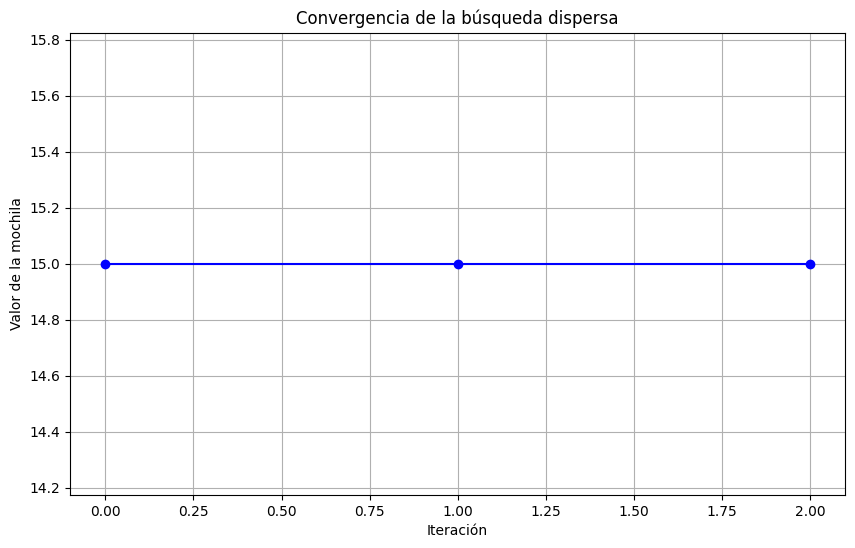


                       FIN DE LA DEMOSTRACIÓN PASO A PASO                       


In [7]:
# Mostrar resultados finales
print("\n" + "="*50)
print("RESULTADOS FINALES DEL ALGORITMO")
print("="*50)

print(f"Mejor valor encontrado: {ss.mejor_valor}")

peso_total = sum(ss.pesos[i] * ss.mejor_solucion[i] for i in range(ss.n_items))
print(f"Peso total: {peso_total}/{ss.capacidad_maxima}")

print("Items seleccionados:")
for i in range(ss.n_items):
    if ss.mejor_solucion[i] == 1:
        print(f"Item {i+1}: Peso={ss.pesos[i]}, Valor={ss.valores[i]}")

# Graficar convergencia
plt.figure(figsize=(10, 6))
plt.plot(range(len(ss.historial_fitness)), ss.historial_fitness, 'b-o')
plt.title("Convergencia de la búsqueda dispersa")
plt.xlabel('Iteración')
plt.ylabel('Valor de la mochila')
plt.grid(True)
plt.show()

print("\n" + "="*80)
print("FIN DE LA DEMOSTRACIÓN PASO A PASO".center(80))
print("="*80)

La mejor solución lleva los ítems 1, 2 y 4 y llena la mochila. La curva de convergencia se mantiene en 15 desde la primera iteración.

### Efecto de los parámetros

Las siguientes celdas corren el método completo, con `ejecutar(verbose=True)`, sobre la misma instancia de cinco ítems y luego sobre una de diez. Antes, generan cinco soluciones aleatorias para mostrar el primer componente por separado.

In [8]:
random.seed(42)
np.random.seed(42)

print("\n" + "="*80)
print("VISUALIZACIÓN DE COMPONENTES DEL SCATTER SEARCH".center(80))
print("="*80)

# Definir un problema pequeño para facilitar la visualización
pesos = [2, 3, 4, 5, 9]
valores = [3, 4, 5, 8, 10]
capacidad_maxima = 10

print("\nPROBLEMA DE LA MOCHILA:")
print("-"*50)
print(f"Capacidad máxima: {capacidad_maxima}")
print("Ítems disponibles:")
for i in range(len(pesos)):
    print(f"  Ítem {i+1}: Peso={pesos[i]}, Valor={valores[i]}, Ratio={valores[i]/pesos[i]:.2f}")

# Crear instancia
ss = ScatterSearch(
    pesos=pesos,
    valores=valores,
    capacidad_maxima=capacidad_maxima,
    tam_poblacion=8,
    tam_refset=4,
    max_iter=3,
    diversificacion_iter=2
)

# 1. VISUALIZACIÓN DE GENERACIÓN DE SOLUCIONES
print("\n" + "="*50)
print("1. GENERACIÓN DE SOLUCIONES ALEATORIAS")
print("="*50)

print("Generando 5 soluciones aleatorias:")
for i in range(5):
    solucion = ss.generar_solucion_aleatoria()
    valor = ss.evaluar_solucion(solucion)
    peso = sum(ss.pesos[j] * solucion[j] for j in range(ss.n_items))
    factible = "Sí" if peso <= ss.capacidad_maxima else "No"
    
    print(f"\nSolución {i+1}: {solucion}")
print("Parámetros del algoritmo:")
print(f"- Tamaño de población: {ss.tam_poblacion}")
print(f"- Tamaño del conjunto de referencia: {ss.tam_refset}")
print(f"- Máximo de iteraciones: {ss.max_iter}")
print(f"- Frecuencia de diversificación: {ss.diversificacion_iter}")


                VISUALIZACIÓN DE COMPONENTES DEL SCATTER SEARCH                 

PROBLEMA DE LA MOCHILA:
--------------------------------------------------
Capacidad máxima: 10
Ítems disponibles:
  Ítem 1: Peso=2, Valor=3, Ratio=1.50
  Ítem 2: Peso=3, Valor=4, Ratio=1.33
  Ítem 3: Peso=4, Valor=5, Ratio=1.25
  Ítem 4: Peso=5, Valor=8, Ratio=1.60
  Ítem 5: Peso=9, Valor=10, Ratio=1.11

1. GENERACIÓN DE SOLUCIONES ALEATORIAS
Generando 5 soluciones aleatorias:

Solución 1: [0, 0, 1, 0, 0]

Solución 2: [0, 0, 0, 1, 0]

Solución 3: [0, 0, 0, 0, 0]

Solución 4: [0, 1, 0, 1, 1]

Solución 5: [0, 0, 1, 1, 1]
Parámetros del algoritmo:
- Tamaño de población: 8
- Tamaño del conjunto de referencia: 4
- Máximo de iteraciones: 3
- Frecuencia de diversificación: 2


La primera corrida usa los mismos parámetros de la demostración paso a paso.


Ejecutando algoritmo con información detallada...

--- INICIO DEL ALGORITMO ---
Población inicial generada: 8 soluciones
Conjunto de referencia inicial creado con 4 soluciones
Mejor solución inicial: 15
Generadas 6 combinaciones de soluciones
Creadas y mejoradas 6 nuevas soluciones
Conjunto de referencia actualizado: 0 nuevas soluciones incorporadas
¡Nueva mejor solución encontrada! Valor: 15
Aplicada diversificación: generadas 8 nuevas soluciones

Resultados finales:
Mejor valor encontrado: 15
Peso total: 10/10
Items seleccionados:
Item 1: Peso=2, Valor=3
Item 2: Peso=3, Valor=4
Item 4: Peso=5, Valor=8


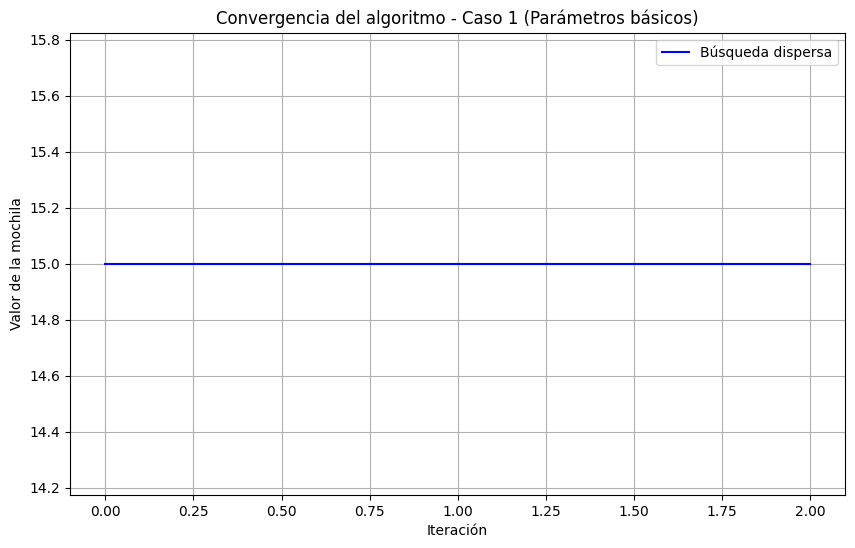

In [9]:
print("\nEjecutando algoritmo con información detallada...")
ss.ejecutar(verbose=True)
ss.mostrar_resultados("Convergencia del algoritmo - Caso 1 (Parámetros básicos)")

La segunda corrida aumenta la población a 40, el conjunto de referencia a 10 y las iteraciones a 50, con diversificación cada 15 iteraciones.


SEGUNDA EJECUCIÓN: Parámetros mejorados
------------------------------------------------------------
Parámetros del algoritmo:
- Tamaño de población: 40
- Tamaño del conjunto de referencia: 10
- Máximo de iteraciones: 50
- Frecuencia de diversificación: 15

Ejecutando algoritmo con información detallada...

--- INICIO DEL ALGORITMO ---
Población inicial generada: 40 soluciones
Conjunto de referencia inicial creado con 10 soluciones
Mejor solución inicial: 15
Generadas 45 combinaciones de soluciones
Creadas y mejoradas 45 nuevas soluciones
Conjunto de referencia actualizado: 0 nuevas soluciones incorporadas
¡Nueva mejor solución encontrada! Valor: 15
Iteración 10/50, Mejor valor: 15

--- ITERACIÓN 10 ---
Generadas 45 combinaciones de soluciones
Creadas y mejoradas 45 nuevas soluciones
Conjunto de referencia actualizado: 0 nuevas soluciones incorporadas
Aplicada diversificación: generadas 40 nuevas soluciones
Iteración 20/50, Mejor valor: 15

--- ITERACIÓN 20 ---
Generadas 45 combinacio

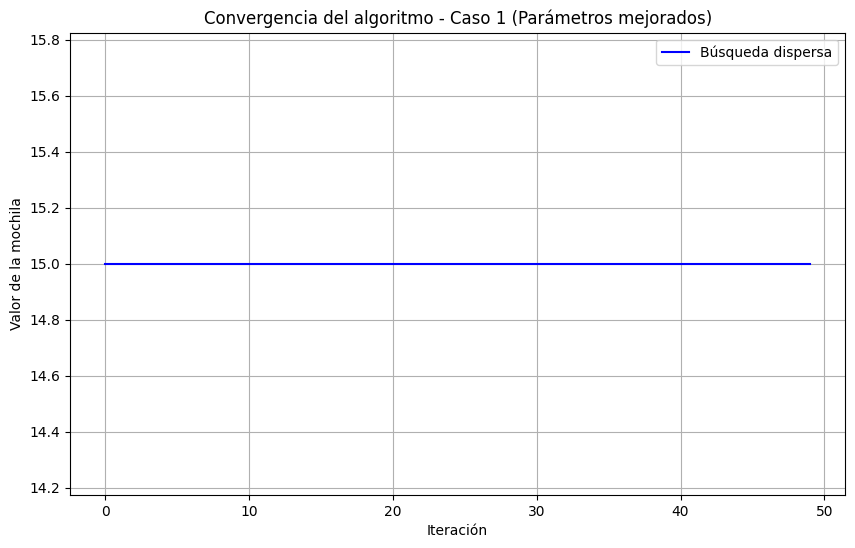


COMPARACIÓN DE RESULTADOS:
------------------------------------------------------------
Ejecución 1 - Mejor valor: 15
Ejecución 2 - Mejor valor: 15


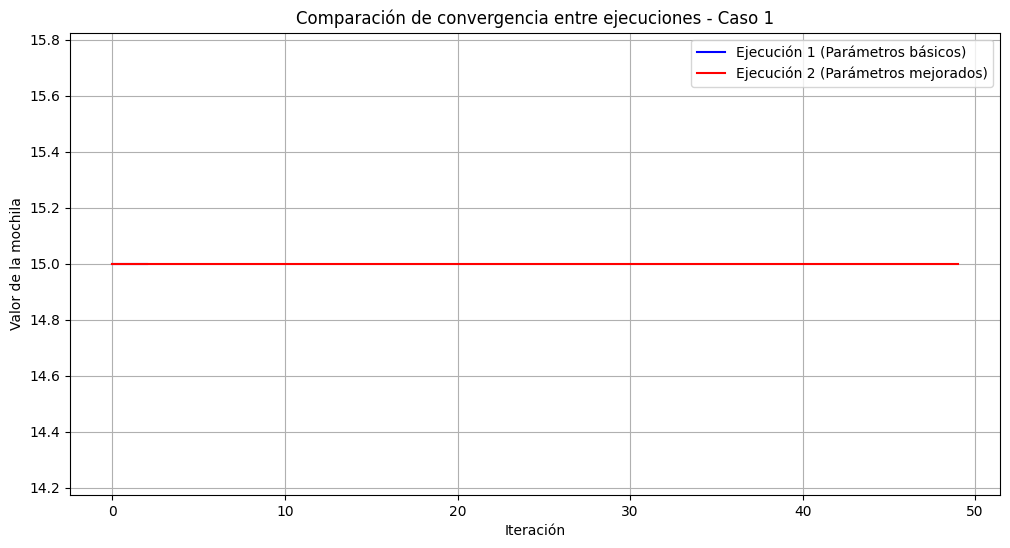

In [10]:
# Segunda ejecución con parámetros mejorados
print("\nSEGUNDA EJECUCIÓN: Parámetros mejorados")
print("-"*60)

scatter_demo2 = ScatterSearch(
    pesos=pesos,
    valores=valores,
    capacidad_maxima=capacidad_maxima,
    tam_poblacion=40,  # Mayor población
    tam_refset=10,     # Mayor conjunto de referencia
    max_iter=50,       # Más iteraciones
    diversificacion_iter=15  # Diferente frecuencia de diversificación
)

print("Parámetros del algoritmo:")
print(f"- Tamaño de población: {scatter_demo2.tam_poblacion}")
print(f"- Tamaño del conjunto de referencia: {scatter_demo2.tam_refset}")
print(f"- Máximo de iteraciones: {scatter_demo2.max_iter}")
print(f"- Frecuencia de diversificación: {scatter_demo2.diversificacion_iter}")

print("\nEjecutando algoritmo con información detallada...")
scatter_demo2.ejecutar(verbose=True)
scatter_demo2.mostrar_resultados("Convergencia del algoritmo - Caso 1 (Parámetros mejorados)")

# Comparación de resultados
print("\nCOMPARACIÓN DE RESULTADOS:")
print("-"*60)
print(f"Ejecución 1 - Mejor valor: {ss.mejor_valor}")
print(f"Ejecución 2 - Mejor valor: {scatter_demo2.mejor_valor}")

# Graficar comparación
plt.figure(figsize=(12, 6))
plt.plot(range(len(ss.historial_fitness)), ss.historial_fitness, 'b-', label='Ejecución 1 (Parámetros básicos)')
plt.plot(range(len(scatter_demo2.historial_fitness)), scatter_demo2.historial_fitness, 'r-', label='Ejecución 2 (Parámetros mejorados)')
plt.title('Comparación de convergencia entre ejecuciones - Caso 1')
plt.xlabel('Iteración')
plt.ylabel('Valor de la mochila')
plt.legend()
plt.grid(True)
plt.show()

Las dos corridas llegan a 15 desde la primera iteración, de modo que en una instancia de cinco ítems los parámetros no marcan diferencia. La salida detallada muestra además que, en todas las iteraciones que informa, ninguna solución distinta de las que ya estaban entra al conjunto de referencia.

La instancia de diez ítems tiene capacidad 35 y pesos entre 5 y 25. Las dos corridas usan la misma población, el mismo conjunto de referencia y el mismo número de iteraciones; solo cambia la frecuencia de diversificación, cada 40 iteraciones en la primera y cada 10 en la segunda.


CASO DEMOSTRATIVO 2: Problema más complejo con diferentes configuraciones
Descripción del problema:
- Número de ítems: 10
- Capacidad de la mochila: 35
- Ítems disponibles:
  * Ítem 1: Peso=10, Valor=50, Ratio=5.00
  * Ítem 2: Peso=15, Valor=60, Ratio=4.00
  * Ítem 3: Peso=20, Valor=90, Ratio=4.50
  * Ítem 4: Peso=8, Valor=30, Ratio=3.75
  * Ítem 5: Peso=12, Valor=40, Ratio=3.33
  * Ítem 6: Peso=5, Valor=10, Ratio=2.00
  * Ítem 7: Peso=18, Valor=70, Ratio=3.89
  * Ítem 8: Peso=25, Valor=100, Ratio=4.00
  * Ítem 9: Peso=15, Valor=55, Ratio=3.67
  * Ítem 10: Peso=10, Valor=35, Ratio=3.50

PRIMERA EJECUCIÓN: Diversificación baja
------------------------------------------------------------
Parámetros del algoritmo:
- Tamaño de población: 50
- Tamaño del conjunto de referencia: 10
- Máximo de iteraciones: 80
- Frecuencia de diversificación: 40

Ejecutando algoritmo con diversificación baja...

--- INICIO DEL ALGORITMO ---
Población inicial generada: 50 soluciones
Conjunto de referencia ini

Iteración 60/80, Mejor valor: 150

--- ITERACIÓN 60 ---
Generadas 45 combinaciones de soluciones
Creadas y mejoradas 45 nuevas soluciones
Conjunto de referencia actualizado: 0 nuevas soluciones incorporadas


Iteración 70/80, Mejor valor: 150

--- ITERACIÓN 70 ---
Generadas 45 combinaciones de soluciones
Creadas y mejoradas 45 nuevas soluciones
Conjunto de referencia actualizado: 0 nuevas soluciones incorporadas
Iteración 80/80, Mejor valor: 150

Resultados finales:
Mejor valor encontrado: 150
Peso total: 35/35
Items seleccionados:
Item 1: Peso=10, Valor=50
Item 8: Peso=25, Valor=100


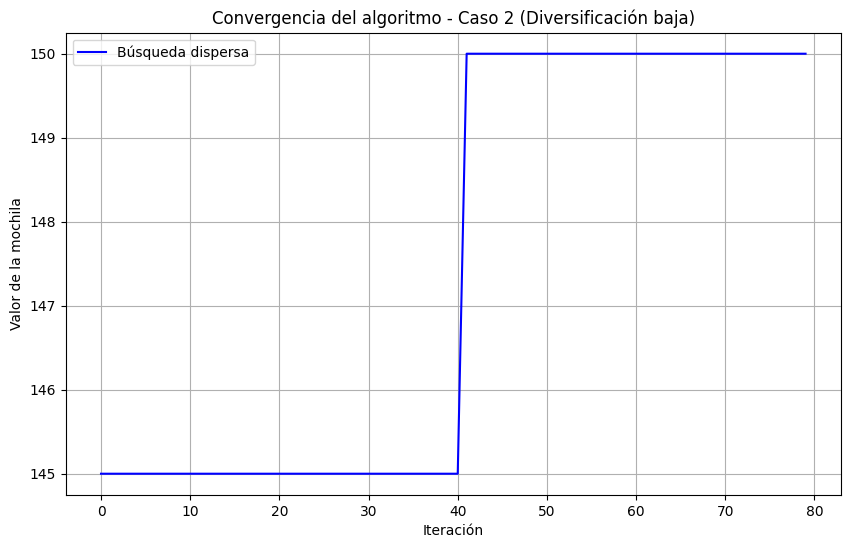

In [11]:
# CASO DEMOSTRATIVO 2: Problema más complejo
print("\n" + "="*80)
print("CASO DEMOSTRATIVO 2: Problema más complejo con diferentes configuraciones")
print("="*80)

# Problema más complejo
pesos = [10, 15, 20, 8, 12, 5, 18, 25, 15, 10]
valores = [50, 60, 90, 30, 40, 10, 70, 100, 55, 35]
capacidad_maxima = 35

print("Descripción del problema:")
print(f"- Número de ítems: {len(pesos)}")
print(f"- Capacidad de la mochila: {capacidad_maxima}")
print("- Ítems disponibles:")
for i in range(len(pesos)):
    print(f"  * Ítem {i+1}: Peso={pesos[i]}, Valor={valores[i]}, Ratio={valores[i]/pesos[i]:.2f}")

# Primera ejecución con diversificación baja
print("\nPRIMERA EJECUCIÓN: Diversificación baja")
print("-"*60)

scatter_demo3 = ScatterSearch(
    pesos=pesos,
    valores=valores,
    capacidad_maxima=capacidad_maxima,
    tam_poblacion=50,
    tam_refset=10,
    max_iter=80,
    diversificacion_iter=40  # Diversificación poco frecuente
)

print("Parámetros del algoritmo:")
print(f"- Tamaño de población: {scatter_demo3.tam_poblacion}")
print(f"- Tamaño del conjunto de referencia: {scatter_demo3.tam_refset}")
print(f"- Máximo de iteraciones: {scatter_demo3.max_iter}")
print(f"- Frecuencia de diversificación: {scatter_demo3.diversificacion_iter}")

print("\nEjecutando algoritmo con diversificación baja...")
scatter_demo3.ejecutar(verbose=True)
scatter_demo3.mostrar_resultados("Convergencia del algoritmo - Caso 2 (Diversificación baja)")


SEGUNDA EJECUCIÓN: Diversificación alta
------------------------------------------------------------
Parámetros del algoritmo:
- Tamaño de población: 50
- Tamaño del conjunto de referencia: 10
- Máximo de iteraciones: 80
- Frecuencia de diversificación: 10

Ejecutando algoritmo con diversificación alta...

--- INICIO DEL ALGORITMO ---
Población inicial generada: 50 soluciones
Conjunto de referencia inicial creado con 10 soluciones
Mejor solución inicial: 150
Generadas 45 combinaciones de soluciones
Creadas y mejoradas 45 nuevas soluciones
Conjunto de referencia actualizado: 1 nuevas soluciones incorporadas
¡Nueva mejor solución encontrada! Valor: 150
Iteración 10/80, Mejor valor: 150

--- ITERACIÓN 10 ---
Generadas 45 combinaciones de soluciones
Creadas y mejoradas 45 nuevas soluciones
Conjunto de referencia actualizado: 0 nuevas soluciones incorporadas
Aplicada diversificación: generadas 50 nuevas soluciones
Iteración 20/80, Mejor valor: 150

--- ITERACIÓN 20 ---
Generadas 45 combina

Conjunto de referencia actualizado: 0 nuevas soluciones incorporadas
Aplicada diversificación: generadas 50 nuevas soluciones
Iteración 70/80, Mejor valor: 150

--- ITERACIÓN 70 ---
Generadas 45 combinaciones de soluciones
Creadas y mejoradas 45 nuevas soluciones
Conjunto de referencia actualizado: 0 nuevas soluciones incorporadas
Aplicada diversificación: generadas 50 nuevas soluciones
Iteración 80/80, Mejor valor: 150

Resultados finales:
Mejor valor encontrado: 150
Peso total: 35/35
Items seleccionados:
Item 1: Peso=10, Valor=50
Item 3: Peso=20, Valor=90
Item 6: Peso=5, Valor=10


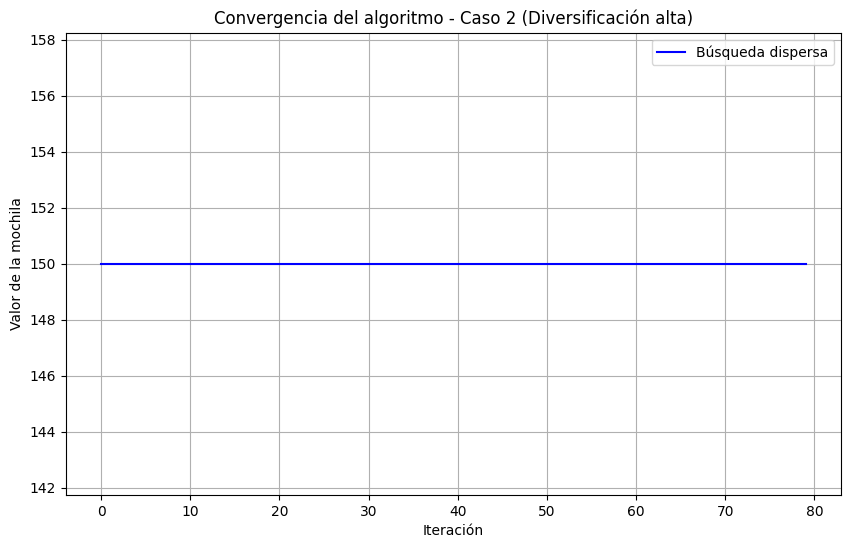

In [12]:
# Segunda ejecución con diversificación alta
print("\nSEGUNDA EJECUCIÓN: Diversificación alta")
print("-"*60)

scatter_demo4 = ScatterSearch(
    pesos=pesos,
    valores=valores,
    capacidad_maxima=capacidad_maxima,
    tam_poblacion=50,
    tam_refset=10,
    max_iter=80,
    diversificacion_iter=10  # Diversificación más frecuente
)

print("Parámetros del algoritmo:")
print(f"- Tamaño de población: {scatter_demo4.tam_poblacion}")
print(f"- Tamaño del conjunto de referencia: {scatter_demo4.tam_refset}")
print(f"- Máximo de iteraciones: {scatter_demo4.max_iter}")
print(f"- Frecuencia de diversificación: {scatter_demo4.diversificacion_iter}")

print("\nEjecutando algoritmo con diversificación alta...")
scatter_demo4.ejecutar(verbose=True)
scatter_demo4.mostrar_resultados("Convergencia del algoritmo - Caso 2 (Diversificación alta)")


COMPARACIÓN DE RESULTADOS:
------------------------------------------------------------
Ejecución 1 (Diversificación baja) - Mejor valor: 150
Ejecución 2 (Diversificación alta) - Mejor valor: 150


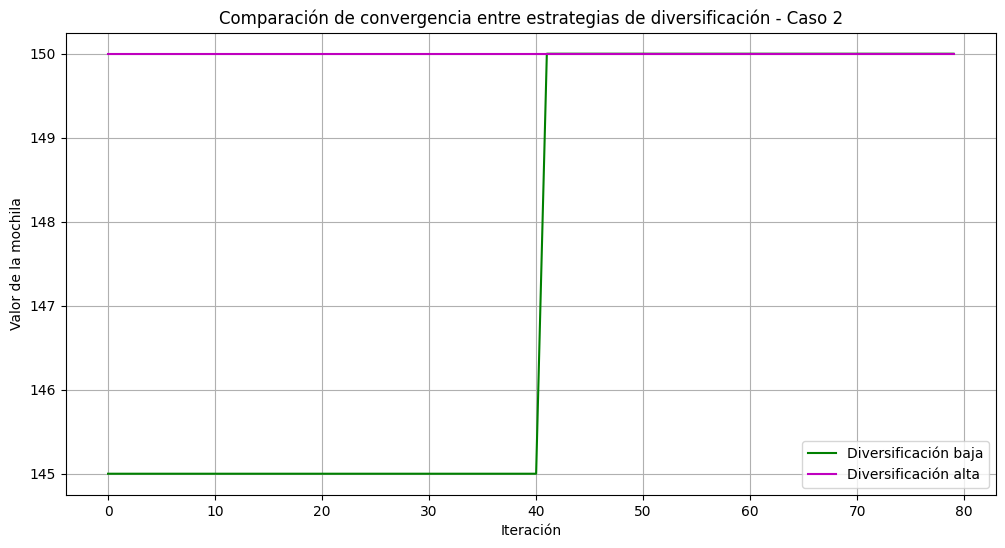


                       FIN DE LA DEMOSTRACIÓN SECUENCIAL                        


In [13]:
# Comparación de resultados
print("\nCOMPARACIÓN DE RESULTADOS:")
print("-"*60)
print(f"Ejecución 1 (Diversificación baja) - Mejor valor: {scatter_demo3.mejor_valor}")
print(f"Ejecución 2 (Diversificación alta) - Mejor valor: {scatter_demo4.mejor_valor}")

# Graficar comparación
plt.figure(figsize=(12, 6))
plt.plot(range(len(scatter_demo3.historial_fitness)), scatter_demo3.historial_fitness, 'g-', label='Diversificación baja')
plt.plot(range(len(scatter_demo4.historial_fitness)), scatter_demo4.historial_fitness, 'm-', label='Diversificación alta')
plt.title('Comparación de convergencia entre estrategias de diversificación - Caso 2')
plt.xlabel('Iteración')
plt.ylabel('Valor de la mochila')
plt.legend()
plt.grid(True)
plt.show()

print("\n" + "="*80)
print("FIN DE LA DEMOSTRACIÓN SECUENCIAL".center(80))
print("="*80)

Con diversificación cada 40 iteraciones, el mejor valor pasa de 60 a 145 en la primera iteración, se queda en 145 hasta la diversificación de la iteración 40 y llega a 150 justo después de ella. Con diversificación cada 10 iteraciones, el mejor valor es 150 desde el comienzo. En este caso la diferencia se debe más a la población inicial que a la frecuencia de diversificación. El generador aleatorio no se reinicia entre las dos corridas, así que la segunda parte de otra población, y su conjunto de referencia inicial ya contiene una solución de valor 150. Con una sola corrida por configuración no se puede atribuir la diferencia al parámetro; el capítulo 10 trata la comparación estadística entre configuraciones.

### Tres instancias adicionales

Las tres instancias siguientes tienen más ítems y usan conjuntos de referencia más grandes. La primera tiene 20 ítems pequeños y capacidad 10. La segunda repite la de diez ítems con otros parámetros. En la tercera, de 15 ítems y capacidad 30, cada valor es exactamente el doble del peso, así que todos los ítems rinden lo mismo por unidad de peso y lo único que importa es llenar la mochila. Su óptimo vale 60, porque cualquier subconjunto con peso exactamente 30 lo alcanza (por ejemplo, los ítems 2, 4 y 11, con pesos 5, 10 y 15).


EJEMPLOS ADICIONALES DE APLICACIÓN DEL ALGORITMO
CASO 1: Problema con muchos ítems de bajo valor/peso
Ejecutando Scatter Search para el problema de la mochila con muchos ítems pequeños...


Iteración 10/80, Mejor valor: 25


Iteración 20/80, Mejor valor: 27


Iteración 30/80, Mejor valor: 27


Iteración 40/80, Mejor valor: 27


Iteración 50/80, Mejor valor: 27


Iteración 60/80, Mejor valor: 27

Iteración 70/80, Mejor valor: 27


Iteración 80/80, Mejor valor: 28

Resultados finales:
Mejor valor encontrado: 28
Peso total: 10/10
Items seleccionados:
Item 9: Peso=1, Valor=3
Item 11: Peso=2, Valor=5
Item 12: Peso=3, Valor=10
Item 13: Peso=1, Valor=2
Item 20: Peso=3, Valor=8


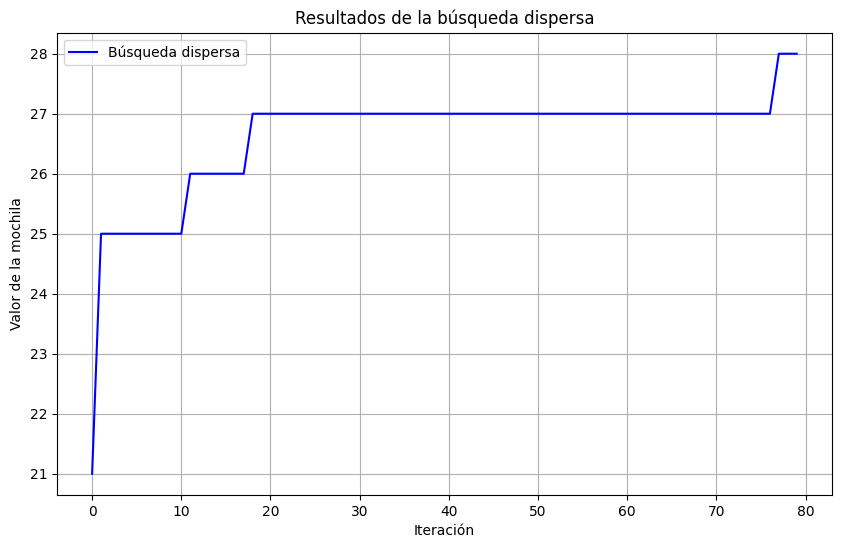

In [14]:
random.seed(42)
np.random.seed(42)

print("\nEJEMPLOS ADICIONALES DE APLICACIÓN DEL ALGORITMO")
print("="*50)

print("CASO 1: Problema con muchos ítems de bajo valor/peso")
# Muchos ítems pequeños, algunos con alto valor
pesos = [1, 1, 1, 2, 2, 2, 1, 1, 1, 1, 2, 3, 1, 2, 1, 1, 1, 2, 1, 3]
valores = [1, 2, 1, 3, 2, 1, 2, 1, 3, 2, 5, 10, 2, 4, 1, 2, 1, 3, 2, 8]
capacidad_maxima = 10

scatter1 = ScatterSearch(
    pesos=pesos,
    valores=valores,
    capacidad_maxima=capacidad_maxima,
    tam_poblacion=100,
    tam_refset=15,
    max_iter=80,
    diversificacion_iter=15
)

print("Ejecutando Scatter Search para el problema de la mochila con muchos ítems pequeños...")
scatter1.ejecutar()
scatter1.mostrar_resultados()



CASO 2: Problema con ítems de alto valor pero gran peso
Ejecutando Scatter Search para el problema con ítems valiosos pero pesados...
Iteración 10/150, Mejor valor: 150
Iteración 20/150, Mejor valor: 150


Iteración 30/150, Mejor valor: 150
Iteración 40/150, Mejor valor: 150
Iteración 50/150, Mejor valor: 150


Iteración 60/150, Mejor valor: 150
Iteración 70/150, Mejor valor: 150
Iteración 80/150, Mejor valor: 150
Iteración 90/150, Mejor valor: 150


Iteración 100/150, Mejor valor: 150
Iteración 110/150, Mejor valor: 150


Iteración 120/150, Mejor valor: 150


Iteración 130/150, Mejor valor: 150
Iteración 140/150, Mejor valor: 150
Iteración 150/150, Mejor valor: 150

Resultados finales:
Mejor valor encontrado: 150
Peso total: 35/35
Items seleccionados:
Item 2: Peso=15, Valor=60
Item 3: Peso=20, Valor=90


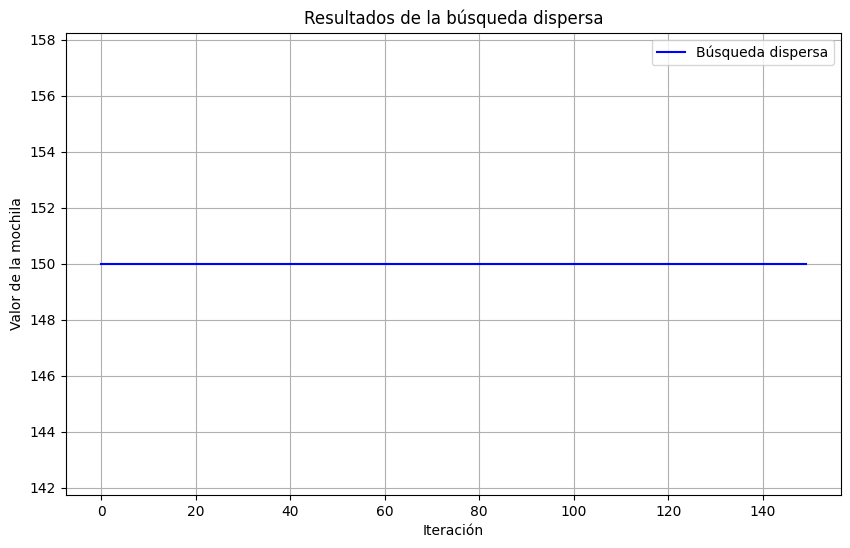

In [15]:
print("\n" + "="*50 + "\n")

print("CASO 2: Problema con ítems de alto valor pero gran peso")
# Pocos ítems valiosos pero pesados
pesos = [10, 15, 20, 8, 12, 5, 18, 25, 15, 10]
valores = [50, 60, 90, 30, 40, 10, 70, 100, 55, 35]
capacidad_maxima = 35

scatter2 = ScatterSearch(
    pesos=pesos,
    valores=valores,
    capacidad_maxima=capacidad_maxima,
    tam_poblacion=80,
    tam_refset=12,
    max_iter=150,
    diversificacion_iter=25
)

print("Ejecutando Scatter Search para el problema con ítems valiosos pero pesados...")
scatter2.ejecutar()
scatter2.mostrar_resultados()



CASO 3: Problema con valores y pesos correlacionados
Ejecutando Scatter Search para el problema con valores proporcionales a pesos...


Iteración 10/200, Mejor valor: 60


Iteración 20/200, Mejor valor: 60


Iteración 30/200, Mejor valor: 60


Iteración 40/200, Mejor valor: 60


Iteración 50/200, Mejor valor: 60


... (11 outputs left out)

Iteración 170/200, Mejor valor: 60


Iteración 180/200, Mejor valor: 60


Iteración 190/200, Mejor valor: 60


Iteración 200/200, Mejor valor: 60

Resultados finales:
Mejor valor encontrado: 60
Peso total: 30/30
Items seleccionados:
Item 1: Peso=3, Valor=6
Item 4: Peso=10, Valor=20
Item 5: Peso=2, Valor=4
Item 13: Peso=8, Valor=16
Item 15: Peso=7, Valor=14


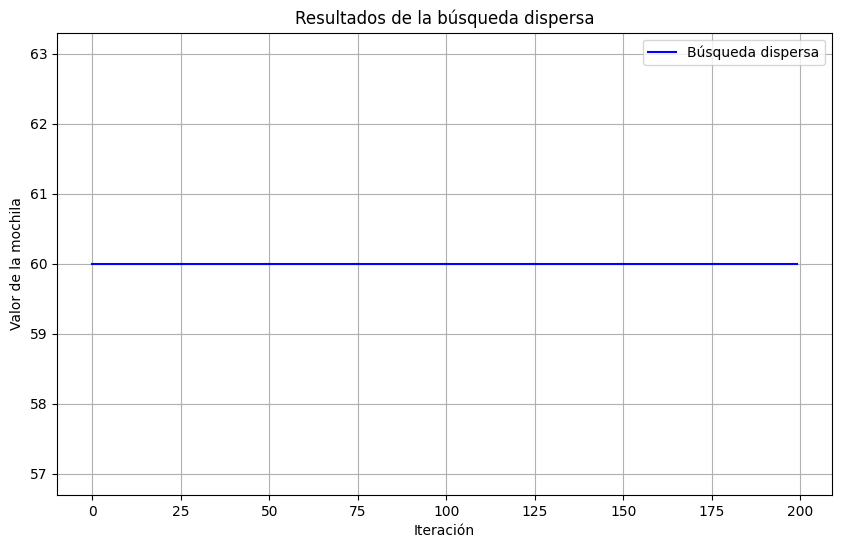

In [16]:
print("\n" + "="*50 + "\n")

print("CASO 3: Problema con valores y pesos correlacionados")
# Valores proporcionales a los pesos (dificulta la decisión)
pesos = [3, 5, 7, 10, 2, 4, 8, 6, 9, 12, 15, 5, 8, 4, 7]
valores = [6, 10, 14, 20, 4, 8, 16, 12, 18, 24, 30, 10, 16, 8, 14]
capacidad_maxima = 30

scatter3 = ScatterSearch(
    pesos=pesos,
    valores=valores,
    capacidad_maxima=capacidad_maxima,
    tam_poblacion=120,
    tam_refset=20,
    max_iter=200,
    diversificacion_iter=30
)

print("Ejecutando Scatter Search para el problema con valores proporcionales a pesos...")
scatter3.ejecutar()
scatter3.mostrar_resultados()

Para saber si la búsqueda llegó al óptimo, la celda siguiente lo calcula por programación dinámica en las cuatro instancias de la sección. El método llena una tabla con el mejor valor alcanzable para cada capacidad entre 0 y $W$, agregando un ítem a la vez.

In [17]:
def optimo_mochila(pesos, valores, capacidad):
    """Valor óptimo de la mochila 0-1 por programación dinámica"""
    mejor = [0] * (capacidad + 1)
    for w, v in zip(pesos, valores):
        for c in range(capacidad, w - 1, -1):
            mejor[c] = max(mejor[c], mejor[c - w] + v)
    return mejor[capacidad]

for nombre, instancia in [("5 ítems", ss), ("10 ítems", scatter2), ("20 ítems", scatter1), ("15 ítems", scatter3)]:
    print(f"{nombre}: óptimo = {optimo_mochila(instancia.pesos, instancia.valores, instancia.capacidad_maxima)}, "
          f"búsqueda dispersa = {instancia.mejor_valor}")

5 ítems: óptimo = 15, búsqueda dispersa = 15
10 ítems: óptimo = 150, búsqueda dispersa = 150
20 ítems: óptimo = 28, búsqueda dispersa = 28
15 ítems: óptimo = 60, búsqueda dispersa = 60


La búsqueda dispersa alcanza el óptimo en las cuatro instancias. En la de 20 ítems lo alcanza solo en las últimas diez iteraciones, después de pasar al menos 50 iteraciones con valor 27; en la de 10 y en la de 15 ítems lo tiene desde las primeras diez iteraciones.

## Flujo mínimo en una red con cotas inferiores

### El problema

El segundo ejemplo trabaja sobre una red dirigida $G = (N, A)$ con un origen $s$ y un destino $t$. Cada arco $(i,j)$ tiene una cota inferior $\ell_{ij}$ y una capacidad $u_{ij}$. Un flujo $\mathbf{x}$ es factible si se conserva en los nodos intermedios y respeta las cotas de cada arco. Su valor es el flujo neto que sale del origen. El problema de flujo mínimo busca el flujo factible de menor valor,

$$\min \; v(\mathbf{x}) = \sum_{(s,j) \in A} x_{sj} - \sum_{(i,s) \in A} x_{is}$$

$$\text{s. a.} \quad \sum_{(i,k) \in A} x_{ik} - \sum_{(k,j) \in A} x_{kj} = 0 \quad \forall k \in N \setminus \{s,t\}, \qquad \ell_{ij} \le x_{ij} \le u_{ij} \quad \forall (i,j) \in A.$$

Sin cotas inferiores, el flujo nulo sería óptimo; son las cotas inferiores las que obligan a mover un flujo mínimo por la red. La red del ejemplo, que construye la función `crear_grafo_ejemplo`, tiene los nodos $s$, $a$, $b$, $c$ y $t$ y siete arcos. Como los dos arcos que llegan a $t$ tienen cotas inferiores de 1 y 3, ningún flujo factible vale menos de 4.

### Representación

Una solución (clase `SolucionMinFlow`) es un diccionario que asigna a cada arco un flujo real. El método `evaluar` revisa la conservación en los nodos intermedios, con una tolerancia de $10^{-6}$, y las cotas de cada arco. La calidad de la solución es su valor $v(\mathbf{x})$ si es factible e infinito si no lo es, y la búsqueda la minimiza.

### Los componentes del método

La clase `ScatterSearchMinFlow` organiza los mismos cinco componentes del ejemplo anterior, más un método de reparación.

1. Generación de diversidad (`diversificacion`). Genera 100 soluciones. La primera sale del método `generar_solucion_inicial_relajada`, que resuelve con `linprog` un modelo lineal que minimiza la suma de los flujos de todos los arcos con un valor de flujo fijo igual a 1. Si `linprog` no encuentra solución, el método devuelve una solución aleatoria. Las otras 99 sortean el flujo de cada arco de manera uniforme entre sus cotas y luego se reparan.
2. Reparación (`reparar_solucion`). Recorre una vez los nodos intermedios. Si un nodo tiene un desbalance $\delta$ entre lo que entra y lo que sale, elige al azar un arco de salida con holgura en la dirección necesaria y le suma $\min\{\delta, u - x\}$ si $\delta > 0$, o $\max\{\delta, \ell - x\}$ si $\delta < 0$. Al final trunca todos los flujos a sus cotas y evalúa la solución. Una sola pasada no garantiza la factibilidad, porque ajustar la salida de un nodo cambia la entrada del siguiente, de modo que algunas soluciones quedan infactibles y con calidad infinita.
3. Mejora (`mejora_local`). Para cada arco, intenta reducir su flujo en 10 %, 5 % y 1 %, sin bajar de la cota inferior; repara la solución y acepta el cambio si queda factible y de menor valor.
4. Actualización del conjunto de referencia (`actualizar_refset`). Toma las $\lfloor b/2 \rfloor$ soluciones de menor valor y completa el conjunto con las más alejadas de las ya elegidas, con el mismo criterio de máxima distancia mínima del ejemplo de la mochila. Aquí la distancia es la euclidiana entre vectores de flujo, $d(\mathbf{x}, \mathbf{y}) = \sqrt{\sum_{a \in A} (x_a - y_a)^2}$.
5. Generación de subconjuntos y combinación (`combinar_soluciones`). Cada par del conjunto de referencia produce dos hijos. El primero es un promedio ponderado arco por arco, $x_a = \lambda_a x^{1}_a + (1-\lambda_a)\, x^{2}_a$, con un $\lambda_a$ uniforme en $[0,1]$ distinto para cada arco. El segundo es un cruce uniforme, en el que cada arco toma el flujo de uno de los dos padres con probabilidad 1/2. Los dos hijos se reparan.

En cada iteración del método `ejecutar` se combinan todos los pares, se mejoran todos los hijos y el conjunto de referencia se reconstruye a partir del conjunto actual más los hijos. A diferencia del ejemplo de la mochila, no hay diversificación periódica. El ejemplo usa un conjunto de referencia de 10 soluciones y 50 iteraciones.

In [18]:
import numpy as np
import networkx as nx
import random
import time
from scipy.optimize import linprog
import matplotlib.pyplot as plt

plt.style.use('default')  # Usar estilo por defecto

In [19]:
class SolucionMinFlow:
    """
    Clase que representa una solución para el problema de flujo mínimo.
    
    Almacena los flujos asignados a cada arco, el grafo de la red, los nodos
    de origen y destino, así como información sobre la factibilidad y calidad
    de la solución.
    """
    def __init__(self, flujos, grafo, origen, destino):
        """
        Inicializa una solución para el problema de flujo mínimo.
        
        Args:
            flujos (dict): Diccionario que mapea arcos (u,v) a valores de flujo
            grafo (DiGraph): Grafo dirigido que representa la red
            origen (node): Nodo origen del flujo
            destino (node): Nodo destino del flujo
        """
        self.flujos = flujos  # Diccionario de flujos en cada arco
        self.grafo = grafo    # Grafo de la red
        self.origen = origen  # Nodo origen
        self.destino = destino  # Nodo destino
        self.valor_flujo = None  # Valor total del flujo
        self.factible = False  # Indica si la solución es factible
        self.calidad = float('inf')  # Medida de calidad (menor es mejor)
    
    def evaluar(self):
        """
        Evalúa la calidad de la solución y verifica su factibilidad.
        
        Comprueba la conservación de flujo en cada nodo y que los flujos
        respeten las capacidades mínimas y máximas de los arcos.
        
        Returns:
            float: Valor de calidad de la solución (valor del flujo si es factible,
                  infinito en caso contrario)
        """
        # Verificar conservación de flujo en cada nodo
        self.factible = True
        for nodo in self.grafo.nodes():
            if nodo == self.origen or nodo == self.destino:
                continue
            
            flujo_entrante = sum(self.flujos.get((i, nodo), 0) for i in self.grafo.predecessors(nodo))
            flujo_saliente = sum(self.flujos.get((nodo, j), 0) for j in self.grafo.successors(nodo))
            
            if abs(flujo_entrante - flujo_saliente) > 1e-6:
                self.factible = False
        
        # Verificar capacidades
        for u, v, data in self.grafo.edges(data=True):
            if self.flujos.get((u, v), 0) < data['lower'] or self.flujos.get((u, v), 0) > data['capacity']:
                self.factible = False
        
        # Calcular valor del flujo
        flujo_saliente_origen = sum(self.flujos.get((self.origen, j), 0) for j in self.grafo.successors(self.origen))
        flujo_entrante_origen = sum(self.flujos.get((i, self.origen), 0) for i in self.grafo.predecessors(self.origen))
        self.valor_flujo = flujo_saliente_origen - flujo_entrante_origen
        
        # Calcular calidad (objetivo es minimizar)
        self.calidad = self.valor_flujo if self.factible else float('inf')
        return self.calidad
    
    def copiar(self):
        """
        Crea una copia profunda de la solución actual.
        
        Returns:
            SolucionMinFlow: Una nueva instancia con los mismos valores
                            pero independiente de la original
        """
        nueva_solucion = SolucionMinFlow(self.flujos.copy(), self.grafo, self.origen, self.destino)
        nueva_solucion.valor_flujo = self.valor_flujo
        nueva_solucion.factible = self.factible
        nueva_solucion.calidad = self.calidad
        return nueva_solucion
    
    def visualizar_solucion(self, titulo="Solución de Flujo Mínimo"):
        """
        Visualiza la solución como un grafo con los flujos en cada arco.
        
        Args:
            titulo (str): Título para la visualización
        """
        plt.figure(figsize=(10, 7))
        
        # Usar un layout más estable para visualización consistente
        pos = nx.spring_layout(self.grafo, seed=42, k=1, iterations=50)
        
        # Dibujar nodos con colores según su tipo
        nx.draw_networkx_nodes(self.grafo, pos, node_color='lightblue', 
                              node_size=700, alpha=0.8, label='Nodos intermedios')
        
        # Resaltar origen y destino con colores distintivos
        nx.draw_networkx_nodes(self.grafo, pos, nodelist=[self.origen], 
                              node_color='green', node_size=800, alpha=0.8, label='Origen')
        nx.draw_networkx_nodes(self.grafo, pos, nodelist=[self.destino], 
                              node_color='red', node_size=800, alpha=0.8, label='Destino')
        
        # Dibujar etiquetas de nodos con mayor tamaño
        nx.draw_networkx_labels(self.grafo, pos, font_weight='bold', font_size=14)
        
        # Dibujar arcos con etiquetas de flujo mejoradas
        edge_labels = {}
        for u, v, data in self.grafo.edges(data=True):
            flujo = self.flujos.get((u, v), 0)
            edge_labels[(u, v)] = f"{flujo:.2f}/{data['capacity']}"
        
        # Colorear arcos según su flujo relativo a la capacidad
        edge_colors = []
        widths = []
        for u, v, data in self.grafo.edges(data=True):
            flujo = self.flujos.get((u, v), 0)
            ratio = flujo / data['capacity']
            
            # Usar un mapa de colores más intuitivo (verde a rojo)
            if ratio < 0.3:
                color = (0.2, 0.8, 0.2, 0.7)  # Verde para flujos bajos
            elif ratio < 0.7:
                color = (0.8, 0.8, 0.2, 0.7)  # Amarillo para flujos medios
            else:
                color = (0.8, 0.2, 0.2, 0.7)  # Rojo para flujos altos
                
            edge_colors.append(color)
            widths.append(1 + 4 * ratio)  # Ancho proporcional al flujo
        
        # Dibujar arcos con flechas más grandes
        nx.draw_networkx_edges(self.grafo, pos, width=widths, edge_color=edge_colors, 
                              arrowsize=25, alpha=0.8, connectionstyle='arc3,rad=0.1')
        
        # Dibujar etiquetas de arcos con mejor formato
        nx.draw_networkx_edge_labels(self.grafo, pos, edge_labels=edge_labels, 
                                    font_size=12, font_weight='bold')
        
        # Añadir título y leyenda
        plt.title(titulo, fontsize=16, fontweight='bold')
        plt.legend(loc='lower left', fontsize=12, markerscale=0.5)
        
        # Añadir información sobre el valor del flujo
        plt.figtext(0.5, 0.01, f"Valor del flujo: {self.valor_flujo:.2f}", 
                   ha='center', fontsize=14, bbox=dict(facecolor='white', alpha=0.8))
        
        plt.axis('off')
        plt.tight_layout(rect=[0, 0.03, 1, 0.95])
        
        plt.show()

In [20]:
class ScatterSearchMinFlow:
    """
    Implementación del algoritmo Scatter Search para resolver el problema de flujo mínimo.
    
    El algoritmo combina diversificación, intensificación y mejora local para
    encontrar soluciones de alta calidad al problema de flujo mínimo en una red.
    """
    def __init__(self, grafo, origen, destino, tam_refset=10, max_iter=100):
        """
        Inicializa el algoritmo Scatter Search.
        
        Args:
            grafo (DiGraph): Grafo dirigido que representa la red
            origen (node): Nodo origen del flujo
            destino (node): Nodo destino del flujo
            tam_refset (int): Tamaño del conjunto de referencia
            max_iter (int): Número máximo de iteraciones
        """
        self.grafo = grafo
        self.origen = origen
        self.destino = destino
        self.tam_refset = tam_refset
        self.max_iter = max_iter
        self.refset = []  # Conjunto de referencia
        self.mejor_solucion = None
        self.historial_mejor = []
        self.solucion_exacta = None  # Para almacenar la solución del modelo exacto
    
    def generar_solucion_inicial_relajada(self):
        """
        Genera una solución inicial usando una relajación lineal del problema.
        
        Utiliza programación lineal para encontrar una solución inicial de buena
        calidad que puede servir como punto de partida para el algoritmo.
        
        Returns:
            SolucionMinFlow: Una solución inicial basada en la relajación lineal
        """
        # Crear modelo relajado (sin restricciones de integralidad)
        arcos = list(self.grafo.edges())
        n_arcos = len(arcos)
        
        # Mapeo de arcos a índices
        arco_a_indice = {arco: i for i, arco in enumerate(arcos)}
        
        # Coeficientes de la función objetivo (todos 1 para minimizar flujo total)
        c = np.ones(n_arcos)
        
        # Restricciones de conservación de flujo
        A_eq = []
        b_eq = []
        
        for nodo in self.grafo.nodes():
            if nodo == self.origen:
                b_eq.append(1)  # Flujo neto saliente = 1 (valor arbitrario)
            elif nodo == self.destino:
                b_eq.append(-1)  # Flujo neto entrante = -1
            else:
                b_eq.append(0)  # Conservación de flujo
            
            fila = np.zeros(n_arcos)
            
            # Arcos salientes (flujo positivo)
            for sucesor in self.grafo.successors(nodo):
                if (nodo, sucesor) in arco_a_indice:
                    fila[arco_a_indice[(nodo, sucesor)]] = 1
            
            # Arcos entrantes (flujo negativo)
            for predecesor in self.grafo.predecessors(nodo):
                if (predecesor, nodo) in arco_a_indice:
                    fila[arco_a_indice[(predecesor, nodo)]] = -1
            
            A_eq.append(fila)
        
        A_eq = np.array(A_eq)
        b_eq = np.array(b_eq)
        
        # Límites de capacidad
        bounds = []
        for u, v, data in self.grafo.edges(data=True):
            bounds.append((data['lower'], data['capacity']))
        
        # Resolver el problema relajado
        resultado = linprog(c, A_eq=A_eq, b_eq=b_eq, bounds=bounds, method='highs')
        
        if resultado.success:
            # Crear solución a partir del resultado
            flujos = {}
            for i, arco in enumerate(arcos):
                flujos[arco] = resultado.x[i]
            
            solucion = SolucionMinFlow(flujos, self.grafo, self.origen, self.destino)
            solucion.evaluar()
            
            # Guardar como solución exacta
            self.solucion_exacta = solucion
            
            return solucion
        else:
            # Si falla, crear una solución aleatoria
            return self.generar_solucion_aleatoria()
    
    def generar_solucion_aleatoria(self):
        """
        Genera una solución aleatoria para el problema.
        
        Asigna valores aleatorios a los flujos en cada arco dentro de sus límites
        y luego repara la solución para hacerla factible.
        
        Returns:
            SolucionMinFlow: Una solución aleatoria factible
        """
        flujos = {}
        for u, v, data in self.grafo.edges(data=True):
            flujos[(u, v)] = random.uniform(data['lower'], data['capacity'])
        
        # Aplicar reparación para hacerla factible
        solucion = SolucionMinFlow(flujos, self.grafo, self.origen, self.destino)
        return self.reparar_solucion(solucion)
    
    def reparar_solucion(self, solucion):
        """
        Repara una solución para hacerla factible.
        
        Ajusta los flujos para garantizar la conservación de flujo en cada nodo
        y que se respeten las capacidades de los arcos.
        
        Args:
            solucion (SolucionMinFlow): Solución a reparar
            
        Returns:
            SolucionMinFlow: Solución reparada y factible
        """
        # Crear una copia para no modificar la original
        nueva_solucion = solucion.copiar()
        
        # Reparar conservación de flujo en cada nodo
        for nodo in self.grafo.nodes():
            if nodo == self.origen or nodo == self.destino:
                continue
            
            flujo_entrante = sum(nueva_solucion.flujos.get((i, nodo), 0) for i in self.grafo.predecessors(nodo))
            flujo_saliente = sum(nueva_solucion.flujos.get((nodo, j), 0) for j in self.grafo.successors(nodo))
            
            # Si hay desequilibrio, ajustar flujos salientes
            if abs(flujo_entrante - flujo_saliente) > 1e-6:
                sucesores = list(self.grafo.successors(nodo))
                if sucesores:
                    # Distribuir la diferencia entre los arcos salientes
                    diferencia = flujo_entrante - flujo_saliente
                    arcos_ajustables = []
                    
                    for j in sucesores:
                        arco = (nodo, j)
                        capacidad = self.grafo[nodo][j]['capacity']
                        limite_inferior = self.grafo[nodo][j]['lower']
                        flujo_actual = nueva_solucion.flujos.get(arco, 0)
                        
                        if diferencia > 0 and flujo_actual < capacidad:
                            arcos_ajustables.append((arco, min(diferencia, capacidad - flujo_actual)))
                        elif diferencia < 0 and flujo_actual > limite_inferior:
                            arcos_ajustables.append((arco, max(diferencia, limite_inferior - flujo_actual)))
                    
                    if arcos_ajustables:
                        # Seleccionar un arco al azar para ajustar
                        arco_elegido, ajuste_max = random.choice(arcos_ajustables)
                        nueva_solucion.flujos[arco_elegido] = nueva_solucion.flujos.get(arco_elegido, 0) + ajuste_max
        
        # Verificar capacidades y ajustar si es necesario
        for u, v, data in self.grafo.edges(data=True):
            arco = (u, v)
            if arco not in nueva_solucion.flujos:
                nueva_solucion.flujos[arco] = data['lower']
            elif nueva_solucion.flujos[arco] < data['lower']:
                nueva_solucion.flujos[arco] = data['lower']
            elif nueva_solucion.flujos[arco] > data['capacity']:
                nueva_solucion.flujos[arco] = data['capacity']
        
        nueva_solucion.evaluar()
        return nueva_solucion
    
    def diversificacion(self, num_soluciones=100):
        """
        Genera un conjunto diverso de soluciones iniciales.
        
        Combina una solución basada en relajación lineal con soluciones
        aleatorias para crear un conjunto inicial diverso.
        
        Args:
            num_soluciones (int): Número de soluciones a generar
            
        Returns:
            list: Lista de soluciones iniciales diversas
        """
        soluciones = []
        
        # Generar solución usando relajación
        sol_relajada = self.generar_solucion_inicial_relajada()
        soluciones.append(sol_relajada)
        
        # Generar soluciones aleatorias
        for _ in range(num_soluciones - 1):
            soluciones.append(self.generar_solucion_aleatoria())
        
        return soluciones
    
    def actualizar_refset(self, soluciones):
        """
        Actualiza el conjunto de referencia con las mejores soluciones.
        
        Selecciona las mejores soluciones por calidad y las más diversas
        para mantener un balance entre intensificación y diversificación.
        
        Args:
            soluciones (list): Lista de soluciones candidatas
        """
        # Ordenar por calidad
        soluciones_ordenadas = sorted(soluciones, key=lambda x: x.calidad)
        
        # Seleccionar las mejores
        mejores = soluciones_ordenadas[:self.tam_refset // 2]
        
        # Seleccionar las más diversas del resto
        resto = soluciones_ordenadas[self.tam_refset // 2:]
        diversas = []
        
        if resto:
            # Medida de diversidad: distancia euclidiana entre vectores de flujo
            for _ in range(self.tam_refset - len(mejores)):
                if not resto:
                    break
                
                # Encontrar la solución más diversa respecto a las ya seleccionadas
                max_distancia = -1
                sol_mas_diversa = None
                idx_mas_diversa = -1
                
                for i, sol in enumerate(resto):
                    # Calcular distancia mínima a las soluciones ya seleccionadas
                    min_distancia = float('inf')
                    
                    for sol_sel in mejores + diversas:
                        # Calcular distancia euclidiana entre flujos
                        distancia = 0
                        for arco in set(sol.flujos.keys()).union(sol_sel.flujos.keys()):
                            val1 = sol.flujos.get(arco, 0)
                            val2 = sol_sel.flujos.get(arco, 0)
                            distancia += (val1 - val2) ** 2
                        distancia = np.sqrt(distancia)
                        
                        min_distancia = min(min_distancia, distancia)
                    
                    if min_distancia > max_distancia:
                        max_distancia = min_distancia
                        sol_mas_diversa = sol
                        idx_mas_diversa = i
                
                if sol_mas_diversa:
                    diversas.append(sol_mas_diversa)
                    resto.pop(idx_mas_diversa)
        
        self.refset = mejores + diversas
    
    def combinar_soluciones(self):
        """
        Combina pares de soluciones del conjunto de referencia.
        
        Utiliza dos métodos de combinación:
        1. Promedio ponderado de flujos
        2. Cruce de arcos (selección aleatoria de valores)
        
        Returns:
            list: Lista de nuevas soluciones generadas por combinación
        """
        nuevas_soluciones = []
        
        for i in range(len(self.refset)):
            for j in range(i+1, len(self.refset)):
                sol1 = self.refset[i]
                sol2 = self.refset[j]
                
                # Combinación por promedio ponderado
                flujos_combinados = {}
                for arco in sorted(set(sol1.flujos.keys()).union(sol2.flujos.keys())):
                    val1 = sol1.flujos.get(arco, 0)
                    val2 = sol2.flujos.get(arco, 0)
                    peso = random.uniform(0, 1)
                    flujos_combinados[arco] = val1 * peso + val2 * (1 - peso)
                
                nueva_sol = SolucionMinFlow(flujos_combinados, self.grafo, self.origen, self.destino)
                nueva_sol = self.reparar_solucion(nueva_sol)
                nuevas_soluciones.append(nueva_sol)
                
                # Combinación por cruce de arcos
                flujos_cruzados = {}
                for arco in sorted(set(sol1.flujos.keys()).union(sol2.flujos.keys())):
                    if random.random() < 0.5:
                        flujos_cruzados[arco] = sol1.flujos.get(arco, 0)
                    else:
                        flujos_cruzados[arco] = sol2.flujos.get(arco, 0)
                
                nueva_sol = SolucionMinFlow(flujos_cruzados, self.grafo, self.origen, self.destino)
                nueva_sol = self.reparar_solucion(nueva_sol)
                nuevas_soluciones.append(nueva_sol)
        
        return nuevas_soluciones
    
    def mejora_local(self, solucion):
        """
        Aplica una búsqueda local para mejorar la solución.
        
        Intenta reducir el flujo en algunos arcos para minimizar
        el valor total del flujo manteniendo la factibilidad.
        
        Args:
            solucion (SolucionMinFlow): Solución a mejorar
            
        Returns:
            SolucionMinFlow: Solución mejorada
        """
        mejor_sol = solucion.copiar()
        mejor_calidad = mejor_sol.calidad
        
        # Intentar reducir el flujo en algunos arcos
        for arco in mejor_sol.flujos:
            flujo_original = mejor_sol.flujos[arco]
            
            # Intentar reducir el flujo
            for reduccion in [0.1, 0.05, 0.01]:
                nueva_sol = mejor_sol.copiar()
                nueva_sol.flujos[arco] = max(self.grafo[arco[0]][arco[1]]['lower'], 
                                            flujo_original - reduccion * flujo_original)
                
                # Reparar para mantener factibilidad
                nueva_sol = self.reparar_solucion(nueva_sol)
                
                if nueva_sol.factible and nueva_sol.calidad < mejor_calidad:
                    mejor_sol = nueva_sol
                    mejor_calidad = nueva_sol.calidad
        
        return mejor_sol
    
    def ejecutar(self):
        """
        Ejecuta el algoritmo Scatter Search completo.
        
        Implementa las fases de diversificación, combinación, mejora y
        actualización del conjunto de referencia durante varias iteraciones.
        
        Returns:
            SolucionMinFlow: La mejor solución encontrada
        """
        print("Iniciando Scatter Search para el problema de Minimum Flow...")
        
        # Fase de diversificación
        print("Fase de diversificación...")
        soluciones_iniciales = self.diversificacion()
        
        # Inicializar conjunto de referencia
        self.actualizar_refset(soluciones_iniciales)
        
        # Guardar la mejor solución inicial
        self.mejor_solucion = min(self.refset, key=lambda x: x.calidad)
        self.historial_mejor.append(self.mejor_solucion.calidad)
        
        print(f"Mejor solución inicial: {self.mejor_solucion.calidad}")
        
        # Iteraciones principales
        for iter in range(self.max_iter):
            if (iter + 1) % 10 == 0:
                print(f"Iteración {iter+1}/{self.max_iter}")
            
            # Fase de combinación
            nuevas_soluciones = self.combinar_soluciones()
            
            # Fase de mejora
            for i in range(len(nuevas_soluciones)):
                nuevas_soluciones[i] = self.mejora_local(nuevas_soluciones[i])
            
            # Actualizar conjunto de referencia
            self.actualizar_refset(self.refset + nuevas_soluciones)
            
            # Actualizar mejor solución
            mejor_actual = min(self.refset, key=lambda x: x.calidad)
            if mejor_actual.calidad < self.mejor_solucion.calidad:
                self.mejor_solucion = mejor_actual
                print(f"  Nueva mejor solución encontrada: {self.mejor_solucion.calidad}")
            
            self.historial_mejor.append(self.mejor_solucion.calidad)
        
        print("\nBúsqueda finalizada.")
        print(f"Mejor valor de flujo encontrado: {self.mejor_solucion.calidad}")
        
        # Graficar convergencia
        plt.figure(figsize=(10, 6))
        plt.plot(range(len(self.historial_mejor)), self.historial_mejor, 'b-', 
                linewidth=2, label='Valor del flujo')
        
        # Si hay solución exacta, añadir línea horizontal
        if self.solucion_exacta:
            plt.axhline(y=self.solucion_exacta.calidad, color='r', linestyle='--', 
                       label=f'Valor óptimo: {self.solucion_exacta.calidad:.4f}')
            
            # Calcular gap porcentual
            gap = ((self.solucion_exacta.calidad - self.mejor_solucion.calidad) / 
                   self.solucion_exacta.calidad) * 100
            plt.text(len(self.historial_mejor) * 0.7, self.mejor_solucion.calidad, 
                     f'Gap: {gap:.2f}%', fontsize=10, verticalalignment='bottom')
        
        plt.title('Convergencia de la búsqueda dispersa para el flujo mínimo', fontsize=14, fontweight='bold')
        plt.xlabel('Iteración', fontsize=12)
        plt.ylabel('Valor del flujo mínimo', fontsize=12)
        plt.grid(True, linestyle='--', alpha=0.7)
        
        # Añadir leyenda solo si hay elementos para mostrar
        if self.solucion_exacta:
            plt.legend(fontsize=12, loc='upper right')
        
        plt.tight_layout()
        plt.show()
        
        # Visualizar soluciones
        if self.solucion_exacta:
            print("\nComparando soluciones:")
            print(f"Valor del flujo (modelo exacto): {self.solucion_exacta.calidad}")
            print(f"Valor del flujo (metaheurística): {self.mejor_solucion.calidad}")
            print(f"Diferencia: {abs(self.solucion_exacta.calidad - self.mejor_solucion.calidad)}")
            print(f"Gap porcentual: {gap:.2f}%")
            
            # Visualizar solución exacta
            self.solucion_exacta.visualizar_solucion("Solución del Modelo Exacto")
            
            # Visualizar solución de la metaheurística
            self.mejor_solucion.visualizar_solucion("Solución de la búsqueda dispersa")
            
            # Visualizar comparación lado a lado
            self.visualizar_comparacion_soluciones()
        
        return self.mejor_solucion
        
    def visualizar_comparacion_soluciones(self):
        """
        Visualiza una comparación lado a lado de la solución óptima y la encontrada
        por el algoritmo Scatter Search.
        """
        if not self.solucion_exacta or not self.mejor_solucion:
            print("No hay soluciones para comparar")
            return
            
        # Crear figura con dos subplots
        fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 7))
        
        # Configuración común para ambos subplots
        pos = nx.spring_layout(self.grafo, seed=42, k=1, iterations=50)
        
        # Función auxiliar para dibujar un grafo en un subplot
        def dibujar_grafo(ax, solucion, titulo):
            # Dibujar nodos
            nx.draw_networkx_nodes(self.grafo, pos, node_color='lightblue', 
                                  node_size=700, alpha=0.8, ax=ax)
            
            # Resaltar origen y destino
            nx.draw_networkx_nodes(self.grafo, pos, nodelist=[self.origen], 
                                  node_color='green', node_size=800, alpha=0.8, ax=ax)
            nx.draw_networkx_nodes(self.grafo, pos, nodelist=[self.destino], 
                                  node_color='red', node_size=800, alpha=0.8, ax=ax)
            
            # Dibujar etiquetas de nodos
            nx.draw_networkx_labels(self.grafo, pos, font_weight='bold', font_size=14, ax=ax)
            
            # Dibujar arcos con etiquetas de flujo
            edge_labels = {}
            for u, v, data in self.grafo.edges(data=True):
                flujo = solucion.flujos.get((u, v), 0)
                edge_labels[(u, v)] = f"{flujo:.2f}/{data['capacity']}"
            
            # Colorear arcos según su flujo relativo a la capacidad
            edge_colors = []
            widths = []
            for u, v, data in self.grafo.edges(data=True):
                flujo = solucion.flujos.get((u, v), 0)
                ratio = flujo / data['capacity']
                
                # Usar un mapa de colores más intuitivo (verde a rojo)
                if ratio < 0.3:
                    color = (0.2, 0.8, 0.2, 0.7)  # Verde para flujos bajos
                elif ratio < 0.7:
                    color = (0.8, 0.8, 0.2, 0.7)  # Amarillo para flujos medios
                else:
                    color = (0.8, 0.2, 0.2, 0.7)  # Rojo para flujos altos
                    
                edge_colors.append(color)
                widths.append(1 + 4 * ratio)  # Ancho proporcional al flujo
            
            # Dibujar arcos con flechas
            nx.draw_networkx_edges(self.grafo, pos, width=widths, edge_color=edge_colors, 
                                  arrowsize=25, alpha=0.8, connectionstyle='arc3,rad=0.1', ax=ax)
            
            # Dibujar etiquetas de arcos
            nx.draw_networkx_edge_labels(self.grafo, pos, edge_labels=edge_labels, 
                                        font_size=12, font_weight='bold', ax=ax)
            
            # Añadir título
            ax.set_title(titulo, fontsize=16, fontweight='bold')
            
            # Añadir información sobre el valor del flujo
            ax.text(0.5, 0.01, f"Valor del flujo: {solucion.valor_flujo:.2f}", 
                   ha='center', fontsize=14, transform=ax.transAxes, 
                   bbox=dict(facecolor='white', alpha=0.8))
            
            ax.axis('off')
        
        # Dibujar solución óptima
        dibujar_grafo(ax1, self.solucion_exacta, "Solución Óptima")
        
        # Dibujar solución encontrada
        dibujar_grafo(ax2, self.mejor_solucion, "Solución de la búsqueda dispersa")
        
        # Añadir título general
        gap = ((self.solucion_exacta.calidad - self.mejor_solucion.calidad) / 
               self.solucion_exacta.calidad) * 100
        fig.suptitle(f"Comparación de Soluciones - Gap: {gap:.2f}%", 
                    fontsize=18, fontweight='bold')
        
        plt.tight_layout(rect=[0, 0.03, 1, 0.95])
        plt.show()

In [21]:
# Ejemplo de uso
def crear_grafo_ejemplo():
    """
    Crea un grafo de ejemplo para el problema de flujo mínimo.
    
    Construye una red con 5 nodos y 7 arcos con capacidades y límites
    inferiores para demostrar el funcionamiento del algoritmo.
    
    Returns:
        tuple: (grafo, origen, destino) donde grafo es un DiGraph de NetworkX
    """
    G = nx.DiGraph()
    
    # Añadir nodos
    G.add_node('s')  # origen
    G.add_node('t')  # destino
    G.add_node('a')
    G.add_node('b')
    G.add_node('c')
    
    # Añadir arcos con capacidades y límites inferiores
    # (origen, destino, {capacidad, límite inferior})
    G.add_edge('s', 'a', capacity=10, lower=1)
    G.add_edge('s', 'b', capacity=8, lower=0)
    G.add_edge('a', 'b', capacity=5, lower=0)
    G.add_edge('a', 'c', capacity=7, lower=2)
    G.add_edge('b', 'c', capacity=6, lower=0)
    G.add_edge('b', 't', capacity=8, lower=1)
    G.add_edge('c', 't', capacity=10, lower=3)
    
    return G, 's', 't'

### Ejecución

Iniciando Scatter Search para el problema de Minimum Flow...
Fase de diversificación...
Mejor solución inicial: 7.291180749613064
  Nueva mejor solución encontrada: 4.633511357860783
  Nueva mejor solución encontrada: 4.073106241239239
  Nueva mejor solución encontrada: 4.020574102087893
  Nueva mejor solución encontrada: 4.001640063747942
  Nueva mejor solución encontrada: 4.000282504142833


  Nueva mejor solución encontrada: 4.000135355490049
Iteración 10/50


  Nueva mejor solución encontrada: 4.000135355490048
Iteración 20/50


Iteración 30/50


Iteración 40/50


Iteración 50/50

Búsqueda finalizada.
Mejor valor de flujo encontrado: 4.000135355490048


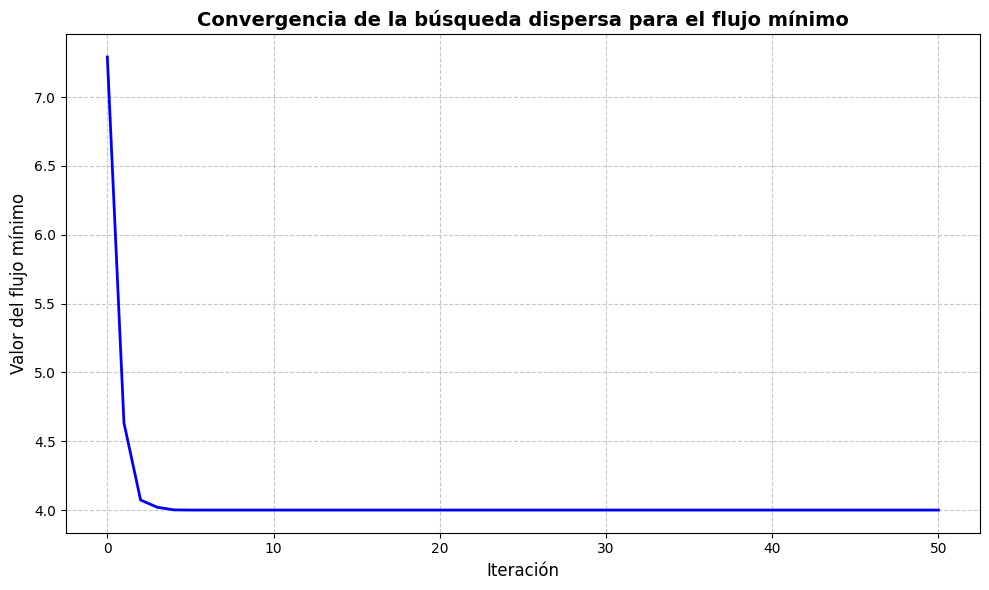

In [22]:
random.seed(42)
np.random.seed(42)

# Crear grafo de ejemplo
grafo, origen, destino = crear_grafo_ejemplo()

# Ejecutar Scatter Search
ss = ScatterSearchMinFlow(grafo, origen, destino, tam_refset=10, max_iter=50)
mejor_solucion = ss.ejecutar()

In [23]:
# Mostrar detalles de la solución
print("\nDetalles de la mejor solución encontrada:")
print(f"Factible: {mejor_solucion.factible}")
print(f"Valor del flujo: {mejor_solucion.valor_flujo}")
print("\nFlujos en los arcos:")
for arco, flujo in sorted(mejor_solucion.flujos.items()):
    print(f"  {arco}: {flujo:.4f}")


Detalles de la mejor solución encontrada:
Factible: True
Valor del flujo: 4.000135355490048

Flujos en los arcos:
  ('a', 'b'): 0.0185
  ('a', 'c'): 2.1368
  ('b', 'c'): 0.8633
  ('b', 't'): 1.0000
  ('c', 't'): 3.0001
  ('s', 'a'): 2.1553
  ('s', 'b'): 1.8448


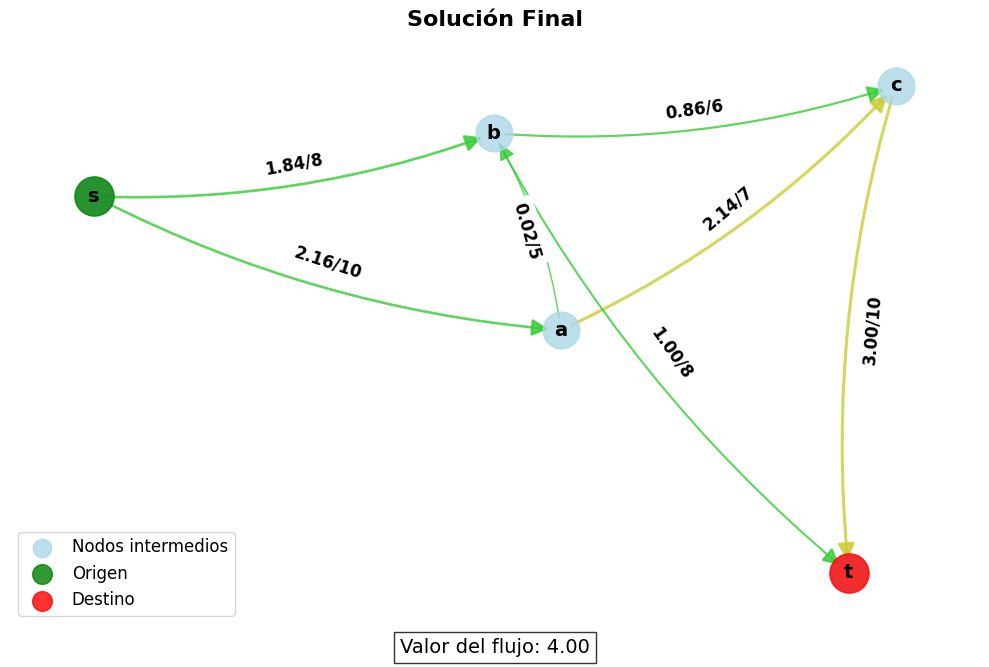

In [24]:
# Visualizar la solución final
mejor_solucion.visualizar_solucion("Solución Final")

La mejor solución inicial vale cerca de 7,3. En las primeras diez iteraciones, la búsqueda baja a un valor cercano a 4, y después solo mejora en los decimales. La mejor solución es factible, y los dos arcos que llegan a $t$ quedan en sus cotas inferiores o muy cerca de ellas.

### Comparación con el modelo lineal

El método `ejecutar` solo dibuja la comparación con el modelo exacto si `generar_solucion_inicial_relajada` encontró solución. La celda siguiente lo verifica.

In [25]:
print("¿linprog resolvió el modelo de generar_solucion_inicial_relajada?", ss.solucion_exacta is not None)

¿linprog resolvió el modelo de generar_solucion_inicial_relajada? False


El modelo de ese método fija el valor del flujo en 1, y en esta red ningún flujo factible vale menos de 4, así que `linprog` declara el modelo infactible y la primera solución de la población resulta aleatoria. Para tener un punto de comparación, la celda siguiente resuelve con `linprog` el modelo de flujo mínimo planteado al comienzo de la sección, que minimiza el valor del flujo con conservación en los nodos intermedios y las cotas de cada arco. Luego guarda esa solución como `solucion_exacta` y llama al método `visualizar_comparacion_soluciones` de la clase. El *gap* que informa ese método es $(v_{\mathrm{LP}} - v_{\mathrm{SS}}) / v_{\mathrm{LP}} \times 100$, de modo que un valor negativo indica que la búsqueda dispersa quedó por encima del óptimo.

Optimization terminated successfully. (HiGHS Status 7: Optimal)
Valor del flujo mínimo (linprog): 4.0000
Valor del flujo (búsqueda dispersa): 4.0001


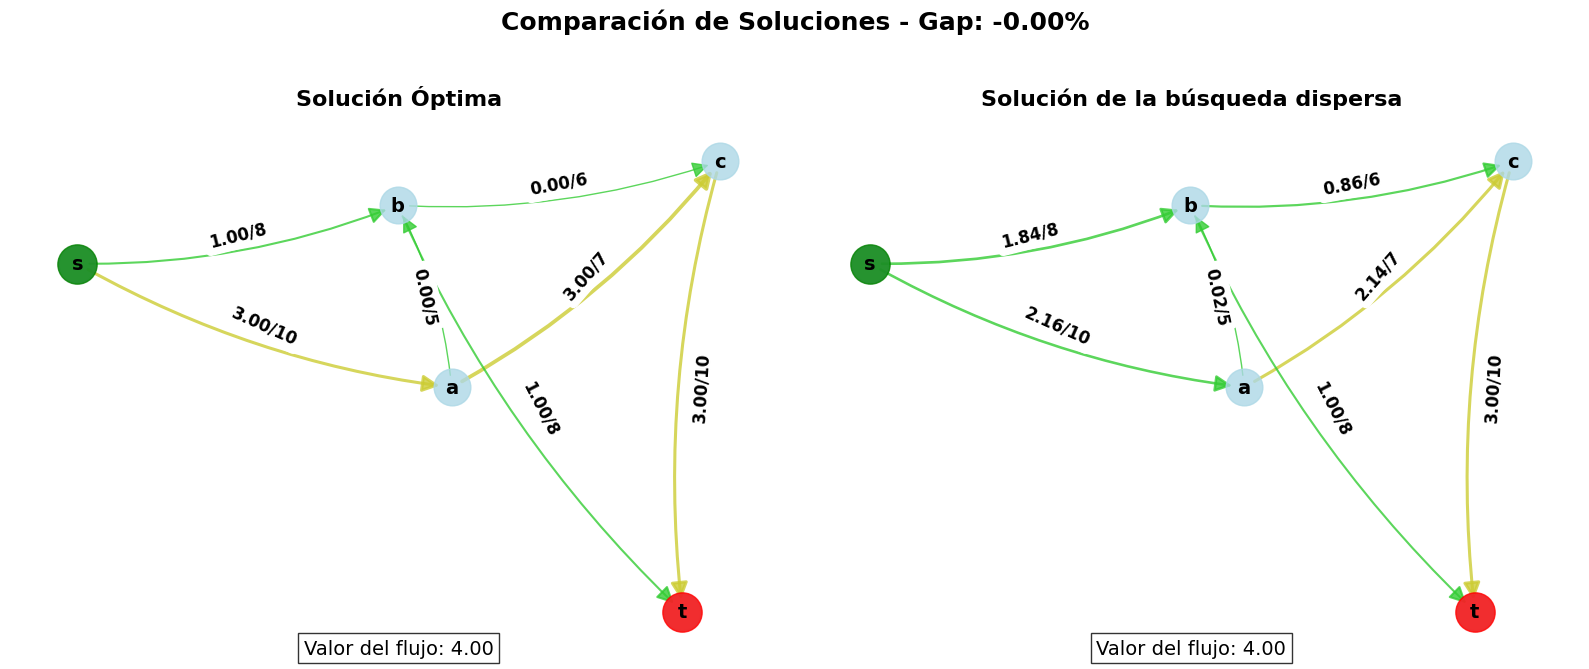

In [26]:
# Modelo lineal del flujo mínimo: minimizar el flujo neto que sale del origen
arcos = list(grafo.edges())
c = np.zeros(len(arcos))
for k, (i, j) in enumerate(arcos):
    if i == origen:
        c[k] += 1
    if j == origen:
        c[k] -= 1

# Conservación de flujo en los nodos intermedios
A_eq, b_eq = [], []
for nodo in grafo.nodes():
    if nodo in (origen, destino):
        continue
    fila = np.zeros(len(arcos))
    for k, (i, j) in enumerate(arcos):
        if j == nodo:
            fila[k] += 1
        if i == nodo:
            fila[k] -= 1
    A_eq.append(fila)
    b_eq.append(0)

cotas = [(grafo[i][j]['lower'], grafo[i][j]['capacity']) for i, j in arcos]
resultado = linprog(c, A_eq=np.array(A_eq), b_eq=np.array(b_eq), bounds=cotas, method='highs')
print(resultado.message)
print(f"Valor del flujo mínimo (linprog): {resultado.fun:.4f}")
print(f"Valor del flujo (búsqueda dispersa): {mejor_solucion.calidad:.4f}")

solucion_lp = SolucionMinFlow(dict(zip(arcos, resultado.x)), grafo, origen, destino)
solucion_lp.evaluar()
ss.solucion_exacta = solucion_lp
ss.visualizar_comparacion_soluciones()

`linprog` encuentra un flujo de valor 4, y la búsqueda dispersa queda a menos de una milésima de ese valor; el *gap* de la figura es prácticamente cero, y su signo negativo indica que quedó por encima. Los dos flujos tienen casi el mismo valor, pero son distintos. El modelo lineal envía tres unidades por $a$ y una por $b$, mientras que la búsqueda dispersa reparte el flujo entre los dos arcos que salen de $s$ y usa los arcos $(a,b)$ y $(b,c)$. El problema tiene muchas soluciones óptimas, y la búsqueda dispersa, que trabaja con flujos reales y reparaciones aleatorias, se acerca a una de ellas sin llegar exactamente.